# Decision Science — Challenge 2
## Portfolio Profit Optimization with PyDO

**Track:** Decision optimization
**Time budget:** 3.5 hours of allocated hands-on time, evenly split across **weeks 2–4**
**Mentoring:** weekly consultation with your assigned mentor is **mandatory**
**Assessment:** week 5 — presentation & defence (shared 2h slot with Challenge 1)
**Prerequisite:** `results/pd_predictions.csv` produced in Challenge 1
**Library:** **PyDO** — Pythonic Decision Optimizer, a lightweight decision-optimization framework (the Python package is named `pydo`)

---

### From a score to a decision

A PD model tells you *how risky* an application is. It does **not** tell you what to do about it.
Turning a score into a decision is where the money is, and it is a constrained optimization
problem — because the business does not simply want maximum profit. It wants maximum profit
**subject to** a risk appetite, a funding budget, a required approval rate, and a product mix that
the commercial and treasury teams can live with.

That is this challenge, and you will solve it with the same tool the Portfolio Management team uses
for real CLX strategy work.

### How PyDO thinks

This is the single most important thing to understand before you write any code. PyDO does **not**
ask you to write an LP by hand. It works like this:

| PyDO concept | What it is here |
|---|---|
| **Portfolio** | Your May 2015 applications — one row per account |
| **Variables** | The treatment space PyDO searches. Here: approve or reject |
| **Functions** | Plain Python functions that compute, per account-treatment pair, what happens — the profit model |
| **Facts** | Constants and assumptions the functions read (cost of funds, recovery rate, …) |
| **Objective** | One calculated variable to maximise |
| **Constraints** | SQL-like aggregate rules over the selected treatments |
| **Flow** | `simulation` (evaluate a fixed policy), `unconstrained` (best per account), `constrained` (the real thing) |

You describe the **economics** and the **business rules**; PyDO compiles them into a MIP and hands
it to SCIP or HiGHS. Your job is to get the economics right and the rules expressed correctly —
not to write a solver interface.

### Problem statement

You are setting the **approval policy for the May 2015 CLX application flow**.

**Decision:** for each application, approve it or reject it. In PyDO terms, one decision variable
`APPROVE_ACTION` with domain `[0, 1]`, giving two treatments per account.

**Objective:** maximise total expected profit of the approved book.

**Constraints — all seven must be in your model**

| # | Constraint | Value |
|---|---|---|
| C1 | Portfolio expected **risk rate** — expected bad volume / disbursed volume | ≤ **22%** |
| C2 | **Approval rate** — approved applications / total applications | ≥ **45%** |
| C3 | **Funding budget** — total disbursed amount | ≤ **350 bn VND** |
| C4 | **Long-tenor mix** — share of disbursed volume with `TENOR_MONTHS ≥ 36` | ≤ **45%** |
| C5 | **Small-ticket access** — share of approved *count* in `CLX_MICRO` | ≥ **12%** |
| C6 | **Pricing optics** — share of approved *count* with `INTEREST_RATE > 40%` | ≤ **20%** |
| C7 | **Policy monotonicity** — approved share must not increase as risk increases, within each product segment | — |

C7 is not a mathematical nicety. A policy that approves more of a riskier band than a safer one
cannot be defended in front of a risk committee, no matter what the objective function says.

### What you must produce

| # | Deliverable | Notes |
|---|---|---|
| 1 | This notebook, completed and runnable | portfolio → economics → project → three flows → distilled policy |
| 2 | `results/optimal_policy.csv` | the **distilled band policy**: one row per policy cell with its approve/reject action and KPIs |
| 3 | `results/constrained_output.csv` | PyDO's account-level export |

### Baselines you must beat (or explain why you cannot)

PyDO gives you both for free, and you should run them **before** the constrained solve:

1. **`simulation` flow** — approve everything. The current-state benchmark.
2. **`unconstrained` flow** — best treatment per account with no business rules. The ceiling.

The usual expectation is `simulation ≤ constrained ≤ unconstrained`. If your numbers break that
ordering, something is wrong and you should find out what before going further.

### Ground rules

1. Optimise on **`PD`**, never on `TARGET`. At decision time the outcome is unknown. `TARGET` is
   allowed in exactly one place: the **back-test at the end**. Optimising on `TARGET` is the
   fastest way to fail this challenge.
2. Every `# TODO` is yours. This notebook gives you structure, the PyDO scaffolding, and a few
   helpers — you are expected to write substantially more than you find here.
3. State your assumptions in the report. The contract parameters and the profit assumptions are
   **synthetic teaching figures**, not figures from a real lender's book. Say so.

> **Implementation note.** This notebook runs on **PyDO** (Pythonic Decision Optimizer), a lightweight library written for this project and imported as `pydo`
> (concepts: Portfolio, Variables, Facts, Functions, Project, Constraints and the `simulation` / `unconstrained` / `constrained`
> flows). The package is in `pydo/` next to this notebook (checked by `tests/`). The solver is HiGHS, reached through
> `scipy.optimize.milp`.

## 0. Verify the environment

In [1]:
# PyDO: the decision-optimization library of this project (src/pydo); the solver backend is HiGHS through scipy.
import pydo as do
import scipy
from pathlib import Path

print("pydo :", do.__version__)
print("scipy:", scipy.__version__, "(HiGHS via scipy.optimize.milp)")

pydo : 0.0.1
scipy: 1.17.1 (HiGHS via scipy.optimize.milp)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

Path("functions").mkdir(exist_ok=True)          # the calculation functions are written here (section 2)
Path("../results/models").mkdir(parents=True, exist_ok=True)   # the distilled policy is saved here (section 8)

## 1. Build the portfolio

One row per application, with your Challenge 1 PD attached.

**The rule that will bite you if you ignore it:** PyDO requires that `WHERE` clauses in aggregate
constraints reference **raw portfolio columns**, never calculated (`v_`) variables. The reason is
structural — aggregate denominators must be fixed before the solver runs, and a calculated variable
depends on which treatment gets selected.

So every field you want to filter a constraint on — risk band, product group, tenor bucket, the
high-IR flag — has to exist as a **column in the portfolio DataFrame** before PyDO ever sees it.
Build them here.

In [3]:
DATA  = "../data/training_data.csv.gz"      # not in the repository: see data/README.md
SCORE = "../results/pd_predictions.csv"   # written by notebook 01
HOLDOUT_MONTH = "2015-05"

df = pd.read_csv(DATA, parse_dates=["TIME"])
app = df[df["TIME"].dt.to_period("M").astype(str) == HOLDOUT_MONTH].copy()

scores = pd.read_csv(SCORE)
app = app.merge(scores, on="ID_APPLICATION", how="left", validate="one_to_one")
assert app["PD"].notna().all(), "every May 2015 application needs a PD"

# The observed bad rate is printed as a CALIBRATION DIAGNOSTIC ONLY (is the PD level right?). TARGET is not used for
# any decision before the back-test of section 9.
print(f"{len(app):,} applications | mean PD {app['PD'].mean():.4f} "
      f"| observed bad rate {app['TARGET'].mean():.4f}")

17,976 applications | mean PD 0.3605 | observed bad rate 0.3629


In [4]:
# --- RAW segmentation columns -- these, and only these, may appear in constraint WHERE clauses ---
# Fixed PD cut-offs (not quantiles): quantile bands move when next month's application mix moves, and a policy whose
# band definitions drift is a policy nobody can monitor. Narrow bands (5 pp) in the low-risk area where most of the
# profit is decided, wider bands above 32%, where nearly every loan is unprofitable anyway.
PD_BINS = [0, .05, .10, .15, .20, .25, .32, .40, .50, .65, 1.01]

app["RISK_BAND"] = pd.cut(app["PD"], PD_BINS, labels=False, right=False).astype(int)
app["TENOR_BUCKET"] = pd.cut(app["TENOR_MONTHS"], [0, 11, 35, 999],
                             labels=["T_SHORT", "T_MID", "T_LONG"]).astype(str)
app["HIGH_IR_FLAG"] = (app["INTEREST_RATE"] > 0.40).astype(int)
app["AMOUNT_M"] = app["AMOUNT_VND"] / 1_000_000        # scaled units -- see the note in section 6

# --- BAU decision column -- the fixed policy the simulation flow will replay (section 4) ---
# A simulation reads its decision from a PORTFOLIO COLUMN, not from a constant, so the policy you benchmark against
# has to exist as data. Approve-everything is one column of 1s.
app["APPROVE_ACTION_BAU"] = 1

# PD only here: TARGET is deliberately not part of this table.
band_tbl = app.groupby("RISK_BAND").agg(n=("PD", "size"), share=("PD", lambda s: len(s) / len(app)),
                                        pd_min=("PD", "min"), mean_pd=("PD", "mean"), pd_max=("PD", "max"),
                                        amount_bn=("AMOUNT_VND", lambda s: s.sum() / 1e9))
display(band_tbl.round(4))

cells_tbl = pd.crosstab(app["PRODUCT_GROUP"], app["RISK_BAND"])
display(cells_tbl)
thin = [(p, b, int(cells_tbl.loc[p, b])) for p in cells_tbl.index for b in cells_tbl.columns if cells_tbl.loc[p, b] < 30]
print(f"product x band cells with fewer than 30 accounts: {len(thin)} of {cells_tbl.size}  "
      f"(empty: {sum(1 for _, _, n in thin if n == 0)})")

,n,share,pd_min,mean_pd,pd_max,amount_bn
RISK_BAND,,,,,,
0,2496,0.1389,0.0005,0.0261,0.0499,95.0582
1,1907,0.1061,0.0500,0.0736,0.1000,67.9457
2,1486,0.0827,0.1000,0.1241,0.1500,50.7284
3,1307,0.0727,0.1500,0.1747,0.2000,43.6670
4,1090,0.0606,0.2000,0.2235,0.2500,35.2457
5,1254,0.0698,0.2500,0.2835,0.3199,40.1717
6,1347,0.0749,0.3200,0.3602,0.3999,41.4407
7,1394,0.0775,0.4001,0.4485,0.4999,42.1219
8,1925,0.1071,0.5000,0.5732,0.6500,55.9861


RISK_BAND,0,1,2,3,4,5,6,7,8,9
PRODUCT_GROUP,,,,,,,,,,
CLX_LARGE,78,54,29,24,17,18,17,23,22,41
CLX_MICRO,333,299,236,229,195,258,273,296,478,1022
CLX_MID,790,519,413,341,275,320,317,274,392,616
CLX_SMALL,1295,1035,808,713,603,658,740,801,1033,2091


product x band cells with fewer than 30 accounts: 7 of 40  (empty: 0)


**Why these bands.** Ten fixed PD bands (the cut points are constants, not quantiles). The cuts are every 5 pp up to 25% and
then 32 / 40 / 50 / 65%: narrow where most of the profit is decided, wider where nearly every loan is unprofitable anyway. The
25–32% band deliberately sits on the break-even area (median break-even PD of the portfolio ≈ 24%, `CLX_SMALL` ≈ 24%, section 2b).
Band sizes are healthy overall (the smallest holds 1,090 accounts, 6.1% of the flow; the largest, PD ≥ 65%, holds 21%), and no
product × band cell is empty. **Thin cells:** 7 of the 40 cells hold fewer than 30 accounts and they are all `CLX_LARGE`
(323 accounts in total, bands 2–8). They are kept in the monotonicity rules (section 6) but `preflight()` flags them, because a
monotonicity rule on 20 accounts is a noisy rule.

In [5]:
# Sampling: the full May flow is ~18k accounts x 2 treatments. The solver handles the full flow, so the FINAL run uses
# 100%; section 6 repeats the solve on a stratified 25% sample and reports both numbers.
# Stratify on EVERY column that appears in a constraint WHERE clause -- otherwise a segment constraint can end up
# with too few (or zero) matching accounts.
SAMPLING = 1.0
STRATIFY = ["RISK_BAND", "PRODUCT_GROUP", "TENOR_BUCKET"]

portfolio = do.Portfolio(
    app,
    key_column="ID_APPLICATION",
    random_sampling=SAMPLING,
    stratify_columns=STRATIFY,
)
print(portfolio)

Portfolio(key='ID_APPLICATION', accounts=17,976 of 17,976 (100.0%), columns=67)


## 2. The economics — PyDO calculation functions

This is the heart of the challenge and where most of your marks are.

PyDO calculation functions are plain Python functions in `.py` files, each with the signature
`def f(obj):`. PyDO runs them **in the order you load them**, once per account-treatment pair.
Each function reads what earlier functions wrote and attaches new attributes to `obj`.

The house naming convention (follow it — mentors will look for it):

| Prefix | Meaning | Example |
|---|---|---|
| `p_` | raw portfolio field | `obj.p_AMOUNT_VND` |
| `a_` | action / decision field | `obj.a_approve_action` |
| `f_` | fact / assumption | `obj.f_cost_of_funds` |
| `v_` | calculated value | `obj.v_exp_profit` |

**Economics of one CLX loan** (annuity repayment, monthly instalments):

- **Interest income** if it performs: `MONTHLY_INSTALLMENT × TENOR_MONTHS − AMOUNT_VND`
- **Credit loss** if it defaults: the client stops paying; you lose the outstanding principal at
  that moment, minus recoveries
- **Cost of funds**: charged on the *average outstanding balance*, not the full ticket
- **Acquisition cost**: fixed per approved loan
- **Servicing cost**: fixed per active month
- **Rejected application**: every value is zero

**Assumptions to use** (synthetic teaching numbers — state that in your report):

| Parameter | Value |
|---|---|
| Cost of funds | 9.0% p.a. on average outstanding |
| Acquisition cost | 300,000 VND per approved loan |
| Servicing cost | 25,000 VND per loan per active month |
| Default timing | after `DEFAULT_AT × TENOR` instalments, `DEFAULT_AT = 0.35` |
| Recovery rate | 20% of outstanding principal at default |

Two tasks: finish the functions, then **sensitivity-test the assumptions**. Recovery rate and
default timing are guesses. Re-run with recovery at 10% and 30% and report how far the optimal
policy moves. A policy that flips completely when recovery changes by 10pp is not shippable.

In [6]:
%%writefile functions/flatten.py
# Step 1 of the pipeline: copy what we need out of obj.account / obj.decision / obj.facts
# into short, conventionally-named attributes. Everything downstream reads these.

def flatten(obj):
    # --- raw portfolio fields (p_) ---
    obj.p_amount        = obj.account["AMOUNT_VND"]
    obj.p_tenor         = obj.account["TENOR_MONTHS"]
    obj.p_ir            = obj.account["INTEREST_RATE"]
    obj.p_installment   = obj.account["MONTHLY_INSTALLMENT"]
    obj.p_pd            = obj.account["PD"]
    obj.p_product_group = obj.account["PRODUCT_GROUP"]

    # --- decision field (a_) ---
    obj.a_approve_action = obj.decision["APPROVE_ACTION"]

    # --- facts (f_) ---
    obj.f_cost_of_funds  = obj.facts.get("cost_of_funds")
    obj.f_acq_cost       = obj.facts.get("acquisition_cost")
    obj.f_servicing_cost = obj.facts.get("servicing_cost")
    obj.f_default_at     = obj.facts.get("default_at")
    obj.f_recovery_rate  = obj.facts.get("recovery_rate")

Overwriting functions/flatten.py


In [7]:
%%writefile functions/economics.py
# Step 2: the loan-level economics. Runs once per account-treatment pair.

def amortisation(obj):
    """Outstanding principal path for this contract.

    For an annuity loan the balance after m instalments has a closed form:
        B(m) = A*(1+r)^m - I*((1+r)^m - 1)/r      with r = IR/12
    Amortisation is back-loaded, so the average outstanding balance is well above A/2 --
    which is exactly why the funding cost cannot be approximated as A/2 * rate * years.
    """
    r = obj.p_ir / 12.0
    obj.v_monthly_rate = r

    def balance(m):
        if r == 0:                                       # interest-free: straight-line repayment
            return max(obj.p_amount - obj.p_installment * m, 0.0)
        return max(obj.p_amount * (1 + r) ** m - obj.p_installment * (((1 + r) ** m - 1) / r), 0.0)

    obj.v_balance_fn = balance

    # months paid before a bad loan defaults
    obj.v_months_to_default = max(round(obj.p_tenor * obj.f_default_at), 1)

    # average outstanding over the full tenor, and over the shortened life of a defaulted loan
    n_full = int(obj.p_tenor)
    n_def  = int(obj.v_months_to_default)
    obj.v_avg_outstanding_good = sum(balance(m) for m in range(n_full + 1)) / (n_full + 1)
    obj.v_avg_outstanding_bad  = sum(balance(m) for m in range(n_def + 1)) / (n_def + 1)
    obj.v_outstanding_at_default = balance(n_def)


def profit_good(obj):
    """Profit if the loan performs to term."""
    obj.v_interest_income = obj.p_installment * obj.p_tenor - obj.p_amount
    obj.v_funding_cost_good = (obj.v_avg_outstanding_good * obj.f_cost_of_funds
                               * obj.p_tenor / 12.0)
    obj.v_servicing_good = obj.f_servicing_cost * obj.p_tenor

    obj.v_profit_good = (obj.v_interest_income
                         - obj.v_funding_cost_good
                         - obj.v_servicing_good
                         - obj.f_acq_cost)


def profit_bad(obj):
    """Profit (negative) if the loan defaults.

    Three things must be right:
      1. interest actually collected before default is NOT installment * months --
         part of every instalment is principal repayment
      2. funding and servicing cost run only over the SHORTENED life
      3. the loss is the OUTSTANDING balance at default, net of recovery -- not the ticket
    """
    m_def = obj.v_months_to_default

    # 1. principal repaid before default, hence the interest part of the instalments collected
    principal_repaid = obj.p_amount - obj.v_outstanding_at_default
    obj.v_interest_collected = obj.p_installment * m_def - principal_repaid

    # 2. funding cost over m_def months on the average outstanding of the shortened life
    obj.v_funding_cost_bad = obj.v_avg_outstanding_bad * obj.f_cost_of_funds * m_def / 12.0
    obj.v_servicing_bad = obj.f_servicing_cost * m_def

    # 3. credit loss = outstanding at default * (1 - recovery rate)
    obj.v_credit_loss = obj.v_outstanding_at_default * (1.0 - obj.f_recovery_rate)

    # the acquisition cost is paid on a bad loan too
    obj.v_profit_bad = (obj.v_interest_collected
                        - obj.v_funding_cost_bad
                        - obj.v_servicing_bad
                        - obj.v_credit_loss
                        - obj.f_acq_cost)


def metrics(obj):
    """Expected values, and the treatment switch that makes a rejected loan cost nothing."""
    # expected profit of BOOKING this loan
    _exp_profit_if_booked = (1.0 - obj.p_pd) * obj.v_profit_good + obj.p_pd * obj.v_profit_bad

    # The decision switch. Every constraint variable must be zero for a rejected account,
    # otherwise rejected loans silently contribute to your portfolio aggregates.
    obj.v_approved = obj.a_approve_action
    obj.v_exp_profit = obj.a_approve_action * _exp_profit_if_booked

    # Scaled to millions of VND. PyDO does not rescale coefficients for you, and a matrix with a
    # 1e9 dynamic range is a numerically fragile matrix -- see coefficient_report() in section 7.
    obj.v_disbursed_amount_m = obj.a_approve_action * obj.p_amount / 1_000_000

    # Numerator of the risk-rate constraint, as a weighted-average input (see C1 in section 6):
    # WEIGHTED_AVG(v_pd_disbursed, v_disbursed_amount_m) = sum(PD * disbursed) / sum(disbursed).
    obj.v_pd_disbursed = obj.p_pd

    # expected bad volume, for the report (millions of VND)
    obj.v_exp_bad_volume_m = obj.a_approve_action * obj.p_pd * obj.p_amount / 1_000_000

    # Kept ONLY for the numerical-conditioning experiment of section 7b: the same quantities in raw VND / in millions.
    obj.v_disbursed_amount = obj.a_approve_action * obj.p_amount
    obj.v_exp_profit_m = obj.v_exp_profit / 1_000_000

Overwriting functions/economics.py


## 3. Assemble the project

`Facts` carry your assumptions, `Variables` define the treatment space, `Functions` are loaded
**in dependency order**, and the objective must name a variable the pipeline actually calculates.

Order matters, in two places:

- The order you list files in `do.Functions([...])` is the execution order. If `metrics` uses
  `v_profit_good`, then `economics.py` must be loaded before it.
- PyDO validates on assignment, so assign `portfolio` and `variables` **before** `functions`, and
  `functions` before `objective`. Assigning the objective first raises an error, because PyDO has
  not yet discovered which calculated variables exist.

In [8]:
project = do.Project(
    name="CLX May-2015 Approval Policy",
    description="Challenge 2 -- profit optimization under business constraints.",
)

facts = do.Facts()
facts.set("cost_of_funds",    value=0.09,    description="Annual funding rate on average outstanding")
facts.set("acquisition_cost", value=300_000, description="VND per approved loan")
facts.set("servicing_cost",   value=25_000,  description="VND per loan per active month")
facts.set("default_at",       value=0.35,    description="Fraction of tenor elapsed at default")
facts.set("recovery_rate",    value=0.20,    description="Recovery on outstanding at default")

project.facts = facts

# The point of Facts: change ONE line and re-run the whole study (the sensitivity analysis of the next phase
# does exactly that instead of editing the .py files).

In [9]:
OUTPUT_VARIABLES = [
    "v_approved",
    "v_disbursed_amount_m",
    "v_exp_profit",
    "v_profit_good",
    "v_profit_bad",
    "v_credit_loss",
    "v_pd_disbursed",
    "v_exp_bad_volume_m",
    # loan-level building blocks, exported so that the economics can be audited line by line
    "v_interest_income",
    "v_avg_outstanding_good",
    "v_funding_cost_good",
    "v_outstanding_at_default",
    "v_interest_collected",
    "v_funding_cost_bad",
]

variables = do.Variables()
variables.set("APPROVE_ACTION", [0, 1])      # 0 = reject, 1 = approve
project.variables = variables
print(project.variables)

project.portfolio = portfolio

project.functions = do.Functions([
    "functions/flatten.py",
    "functions/economics.py",
])

project.objective = "v_exp_profit"
project.direction = "maximize"

project.output_variables = OUTPUT_VARIABLES

print(project)

Variables(APPROVE_ACTION: [0, 1]; 2 treatments)
Project('CLX May-2015 Approval Policy'
  portfolio  : Portfolio(key='ID_APPLICATION', accounts=17,976 of 17,976 (100.0%), columns=67)
  variables  : Variables(APPROVE_ACTION: [0, 1]; 2 treatments)
  functions  : Functions(flatten.py:flatten -> economics.py:amortisation -> economics.py:profit_good -> economics.py:profit_bad -> economics.py:metrics)
  facts      : 5 defined
  objective  : maximize v_exp_profit
  outputs    : ['v_approved', 'v_disbursed_amount_m', 'v_exp_profit', 'v_profit_good', 'v_profit_bad', 'v_credit_loss', 'v_pd_disbursed', 'v_exp_bad_volume_m', 'v_interest_income', 'v_avg_outstanding_good', 'v_funding_cost_good', 'v_outstanding_at_default', 'v_interest_collected', 'v_funding_cost_bad']
)


### 2b. Sanity-check the economics against an independent calculation

A profit model that has never been checked against an independent calculation is a profit model you cannot defend.
The check below runs the real pipeline (approve everything, so every loan is booked) and recomputes five contracts
month by month, with a schedule built from the recursion `B_m = B_{m-1}(1+r) - I` instead of the closed form the
functions use.

In [10]:
# Run the pipeline on "approve everything" just to read the loan-level amounts of every contract.
probe = project.scenario(name="probe", flow="simulation", decisions={"APPROVE_ACTION": 1}).build().optimize()
loan = probe.export().merge(app[["ID_APPLICATION", "PRODUCT_GROUP", "TENOR_MONTHS", "AMOUNT_VND", "INTEREST_RATE",
                                 "MONTHLY_INSTALLMENT", "PD"]], on="ID_APPLICATION")

# Five contracts spanning small / large ticket and short / long tenor.
pick = {
    "micro, short":   loan[(loan.PRODUCT_GROUP == "CLX_MICRO") & (loan.TENOR_MONTHS == 6)].sort_values("AMOUNT_VND").index[0],
    "small, median":  (loan[loan.PRODUCT_GROUP == "CLX_SMALL"].AMOUNT_VND - 25e6).abs().idxmin(),
    "mid, long":      loan[(loan.PRODUCT_GROUP == "CLX_MID") & (loan.TENOR_MONTHS == 36)].sort_values("AMOUNT_VND").index[-1],
    "large, longest": loan[(loan.PRODUCT_GROUP == "CLX_LARGE") & (loan.TENOR_MONTHS == 60)].sort_values("AMOUNT_VND").index[-1],
    "micro, high IR": loan[(loan.PRODUCT_GROUP == "CLX_MICRO")].sort_values("INTEREST_RATE").index[-1],
}
FACT = dict(cof=0.09, acq=300_000, serv=25_000, dflt=0.35, rec=0.20)

def independent(row):
    A_, n, I, r = row.AMOUNT_VND, int(row.TENOR_MONTHS), row.MONTHLY_INSTALLMENT, row.INTEREST_RATE / 12
    bal, interest = [A_], []
    for _ in range(n):                                   # month-by-month schedule, no closed form
        interest.append(bal[-1] * r)
        bal.append(max(bal[-1] * (1 + r) - I, 0.0))
    bal, interest = np.array(bal), np.array(interest)
    m = max(round(n * FACT["dflt"]), 1)
    good = interest.sum() - FACT["cof"] * bal.mean() * n / 12 - FACT["serv"] * n - FACT["acq"]
    loss = bal[m] * (1 - FACT["rec"])
    bad = interest[:m].sum() - FACT["cof"] * bal[:m + 1].mean() * m / 12 - FACT["serv"] * m - loss - FACT["acq"]
    return dict(interest_income=interest.sum(), avg_outstanding=bal.mean(), funding_cost=FACT["cof"] * bal.mean() * n / 12,
                loss_on_default=loss, profit_good=good, profit_bad=bad)

rows = []
for label, idx in pick.items():
    r = loan.loc[idx]
    ind = independent(r)
    pipe = dict(interest_income=r.v_interest_income, avg_outstanding=r.v_avg_outstanding_good,
                funding_cost=r.v_funding_cost_good, loss_on_default=r.v_credit_loss,
                profit_good=r.v_profit_good, profit_bad=r.v_profit_bad)
    rows.append({"contract": label, "amount_m": r.AMOUNT_VND / 1e6, "tenor": int(r.TENOR_MONTHS), "IR": r.INTEREST_RATE,
                 **{f"{k}": pipe[k] / 1e6 for k in pipe}, "max |diff| (VND)": max(abs(pipe[k] - ind[k]) for k in pipe)})
chk = pd.DataFrame(rows).set_index("contract")
display(chk.round(3))
# MONTHLY_INSTALLMENT is rounded to whole VND, so the month-by-month schedule ends with a residual balance of a few VND
# (28 VND on an 83 m loan), which the closed form `installment * tenor - amount` treats as repaid. Anything beyond
# ~1 VND per month of tenor would be a real discrepancy.
assert (chk["max |diff| (VND)"] <= chk["tenor"] * 1.0).all(), "the pipeline disagrees with the independent calculation"
print("pipeline == independent month-by-month schedule for all five contracts (amounts in millions of VND; "
      f"largest difference {chk['max |diff| (VND)'].max():.1f} VND = installment rounding)")

,amount_m,tenor,IR,interest_income,avg_outstanding,funding_cost,loss_on_default,profit_good,profit_bad,max |diff| (VND)
contract,,,,,,,,,,
"micro, short",5.0,6,0.405,0.606,2.569,0.116,2.754,0.041,-2.856,1.952
"small, median",25.0,48,0.210,12.146,14.178,5.104,14.719,5.542,-11.675,34.686
"mid, long",98.5,36,0.310,53.923,56.470,15.247,58.205,37.477,-37.945,16.715
"large, longest",250.0,60,0.193,141.671,144.328,64.948,150.402,74.924,-110.892,19.647
"micro, high IR",5.1,3,0.500,0.431,2.585,0.058,2.775,-0.002,-2.920,0.510


pipeline == independent month-by-month schedule for all five contracts (amounts in millions of VND; largest difference 34.7 VND = installment rounding)


In [11]:
# Is a loan worth booking at all?  E[profit] = (1-PD)*G + PD*B  >  0   <=>   PD < PD* = G / (G - B)   (G > 0 > B).
loan["breakeven_pd"] = loan["v_profit_good"] / (loan["v_profit_good"] - loan["v_profit_bad"])
loan["profitable"] = loan["PD"] < loan["breakeven_pd"]
loan["TENOR_BUCKET"] = app.set_index("ID_APPLICATION").loc[loan["ID_APPLICATION"], "TENOR_BUCKET"].to_numpy()

print(f"share of applications with E[profit] > 0: {loan['profitable'].mean():.1%}  "
      f"| median break-even PD {loan['breakeven_pd'].median():.3f}")
seg = loan.groupby("PRODUCT_GROUP").agg(n=("PD", "size"), median_breakeven_pd=("breakeven_pd", "median"),
                                        median_pd=("PD", "median"), share_profitable=("profitable", "mean"),
                                        median_profit_good_m=("v_profit_good", lambda s: s.median() / 1e6),
                                        median_profit_bad_m=("v_profit_bad", lambda s: s.median() / 1e6))
display(seg.round(3))
seg2 = loan.groupby(["PRODUCT_GROUP", "TENOR_BUCKET"]).agg(n=("PD", "size"), median_breakeven_pd=("breakeven_pd", "median"),
                                                           share_profitable=("profitable", "mean"))
display(seg2[seg2["n"] >= 30].round(3))

# why: fixed costs against the interest a small, short loan can earn
m = loan[(loan.PRODUCT_GROUP == "CLX_MICRO") & (loan.TENOR_MONTHS <= 6)]
fixed = FACT["acq"] + FACT["serv"] * m.TENOR_MONTHS
print(f"\nCLX_MICRO, tenor <= 6 months ({len(m):,} loans): median ticket {m.AMOUNT_VND.median() / 1e6:.1f} m, "
      f"median interest income {m.v_interest_income.median() / 1e6:.2f} m, fixed costs (acquisition + servicing) "
      f"{fixed.median() / 1e6:.2f} m = {fixed.median() / m.v_interest_income.median():.0%} of the interest")

share of applications with E[profit] > 0: 44.4%  | median break-even PD 0.241


,n,median_breakeven_pd,median_pd,share_profitable,median_profit_good_m,median_profit_bad_m
PRODUCT_GROUP,,,,,,
CLX_LARGE,323,0.457,0.153,0.811,44.141,-49.202
CLX_MICRO,3619,0.075,0.395,0.158,0.485,-5.864
CLX_MID,4257,0.387,0.210,0.678,15.359,-23.054
CLX_SMALL,9777,0.236,0.294,0.436,3.796,-11.829


n  median_breakeven_pd  share_profitable
PRODUCT_GROUP TENOR_BUCKET                                             
CLX_LARGE     T_LONG         261                0.497             0.854
              T_MID           61                0.335             0.639
CLX_MICRO     T_LONG          34                0.481             0.706
              T_MID          925                0.215             0.357
              T_SHORT       2660                0.048             0.082
CLX_MID       T_LONG        1996                0.506             0.811
              T_MID         2074                0.321             0.587
              T_SHORT        187                0.139             0.267
CLX_SMALL     T_LONG        1150                0.493             0.754
              T_MID         5657                0.278             0.494
              T_SHORT       2970                0.112             0.204


CLX_MICRO, tenor <= 6 months (2,092 loans): median ticket 10.4 m, median interest income 0.75 m, fixed costs (acquisition + servicing) 0.38 m = 50% of the interest


**What the economics check says.**

* **The pipeline is right:** for five contracts spanning small / large tickets and short / long tenors, every building block
  (interest income, average outstanding, funding cost, loss on default, profit if good, profit if bad) matches an independent
  month-by-month schedule. The largest difference is 34.7 VND on a 250 m loan: `MONTHLY_INSTALLMENT` is rounded to whole VND, so
  the schedule ends with a residual balance of a few dong. Signs and magnitudes are plausible (profit if good is positive,
  profit if bad is negative and several times larger in absolute value).
* **Only 44.4% of the applications have a positive expected profit** (median break-even PD 24%). The picture differs sharply by
  product: `CLX_LARGE` 81% profitable (median break-even PD 46% against a median PD of 15%), `CLX_MID` 68% (39% vs 21%),
  `CLX_SMALL` 44% (24% vs 29%) and **`CLX_MICRO` only 16%** (break-even PD 7.5% against a median PD of 39.5%).
* **Why small short-tenor loans do not pay.** Look at `CLX_MICRO` with a tenor of at most 6 months (2,092 loans, 12% of the flow): the
  median ticket is 10.4 m VND and the median interest income only 0.75 m, while the **fixed** costs (300 k acquisition + 25 k per
  month of servicing) take 0.38 m, i.e. **50% of the interest**. The upside is capped by a short life and a small ticket,
  whereas a default (after 35% of the tenor) still leaves a large part of the principal outstanding (about 70% for the short micro
  loan checked above): the net loss is several times the profit of a good loan. For micro loans with a tenor under 12 months the break-even PD is 4.8%, so only 8% of them
  are worth booking. This is the root of the tension with C5 (micro ≥ 12% of the approved count): the business asks for access to
  exactly the segment where the economics are worst.

## 4. Baseline 1 — `simulation`: approve everything

The `simulation` flow evaluates a **fixed** policy. It does not call a solver; it registers the
given decision as selected and computes the objective. That makes it the natural home for your
business-as-usual benchmark.

**The decision comes from a portfolio column.** `variable_to_decision` maps a PyDO decision
variable onto a column that already exists in the portfolio — keys are decision-variable names,
values are column names:

```
variable_to_decision={"APPROVE_ACTION": "APPROVE_ACTION_BAU"}
```

That is why you wrote `APPROVE_ACTION_BAU` back in section 1. It costs one column and buys you
something a constant cannot: **any** fixed policy that can be written as data can now be
simulated — last month's real decisions, the current cut-off, a challenger rule — each as its own
column and its own simulation scenario. Your profit bridge gets a real left-hand end.

Two things to get right:

- The column must exist in the portfolio **before** `do.Portfolio(...)` was constructed. Adding it
  to `app` after the fact does not help — re-run section 1.
- **Never pass both `decisions` and `variable_to_decision`** to the same scenario. PyDO rejects
  that outright, and the error is easy to misread as a mapping problem.

Pass the constraint set here too — but note the ordering: `constraints` is not defined until
section 6, so the first run of this cell cannot take it. Come back after section 6, re-create the
scenario with `constraints=constraints`, and call `constraint_report()`. Simulation does not
*enforce* the rules; the report simply tells you which ones today's approve-everything flow
already violates — which is the first slide of your presentation.

In [12]:
# The BAU decision is read per account from the portfolio column written in section 1.
bau = project.scenario(
    name="BAU -- approve everything",
    description="Current-state benchmark: no credit policy at all.",
    flow="simulation",
    variable_to_decision={"APPROVE_ACTION": "APPROVE_ACTION_BAU"},
)
bau.build()
bau.optimize()
print("BAU average objective per account:", round(bau.score, 1))
print(f"BAU TOTAL expected profit (full portfolio): {bau.total_portfolio / 1e9:,.2f} bn VND "
      f"(sampling fraction {portfolio.sampling_fraction:.0%}, scale x{portfolio.scale:.2f})")

# --- the KPIs behind C1..C6, computed by hand from the export (cross-check of constraint_report() later) ---
THRESHOLDS = {"C1 risk rate": ("<=", 0.22), "C2 approval rate": (">=", 0.45), "C3 volume (bn VND)": ("<=", 350.0),
              "C4 long-tenor share": ("<=", 0.45), "C5 micro share": (">=", 0.12), "C6 high-IR share": ("<=", 0.20)}

def kpis(scenario):
    """The constraint KPIs of the assignment a scenario selected, from its export (no solver code involved)."""
    sel = scenario.export()
    d = app.set_index("ID_APPLICATION").loc[sel["ID_APPLICATION"]]
    x, scale = sel["APPROVE_ACTION"].to_numpy(), scenario.project.portfolio.scale
    amt = d["AMOUNT_VND"].to_numpy() * x
    return {"C1 risk rate": float((d["PD"].to_numpy() * amt).sum() / amt.sum()),
            "C2 approval rate": float(x.mean()),
            "C3 volume (bn VND)": float(amt.sum() * scale / 1e9),
            "C4 long-tenor share": float(amt[(d["TENOR_BUCKET"] == "T_LONG").to_numpy()].sum() / amt.sum()),
            "C5 micro share": float(x[(d["PRODUCT_GROUP"] == "CLX_MICRO").to_numpy()].sum() / x.sum()),
            "C6 high-IR share": float(x[(d["HIGH_IR_FLAG"] == 1).to_numpy()].sum() / x.sum()),
            "expected profit (bn VND)": float(scenario.total_portfolio / 1e9)}

def kpi_table(**scenarios):
    out = {name: kpis(s) for name, s in scenarios.items()}
    tbl = pd.DataFrame(out)
    for k, (op, thr) in THRESHOLDS.items():
        tbl.loc[k, "limit"] = f"{op} {thr}"
    return tbl

kpi_table(BAU=bau).round(4)

BAU average objective per account: 666339.7
BAU TOTAL expected profit (full portfolio): 11.98 bn VND (sampling fraction 100%, scale x1.00)


,BAU,limit
C1 risk rate,0.3285,<= 0.22
C2 approval rate,1.0000,>= 0.45
C3 volume (bn VND),574.3773,<= 350.0
C4 long-tenor share,0.3328,<= 0.45
C5 micro share,0.2013,>= 0.12
C6 high-IR share,0.1799,<= 0.2
expected profit (bn VND),11.9781,NaN


## 5. Baseline 2 — `unconstrained`: the ceiling

`unconstrained` picks the best treatment per account with no portfolio-level rules. With an
approve/reject decision this reduces to *approve exactly the loans with positive expected profit* —
which is a useful thing to see stated as an optimization result rather than a filter.

This is the ceiling. The constrained answer must sit below it, and the gap between the two is the
price of your business rules.

In [13]:
unconstrained = project.scenario(
    name="Unconstrained",
    description="Best treatment per account, no business constraints.",
    flow="unconstrained",
)
unconstrained.build(n_jobs=-1)
unconstrained.optimize()
print("Unconstrained average objective per account:", round(unconstrained.score, 1))
print(f"Unconstrained TOTAL expected profit: {unconstrained.total_portfolio / 1e9:,.2f} bn VND")

kpi_table(BAU=bau, Unconstrained=unconstrained).round(4)

Unconstrained average objective per account: 3403392.6
Unconstrained TOTAL expected profit: 61.18 bn VND


,BAU,Unconstrained,limit
C1 risk rate,0.3285,0.1462,<= 0.22
C2 approval rate,1.0000,0.4443,>= 0.45
C3 volume (bn VND),574.3773,324.4531,<= 350.0
C4 long-tenor share,0.3328,0.4787,<= 0.45
C5 micro share,0.2013,0.0715,>= 0.12
C6 high-IR share,0.1799,0.0769,<= 0.2
expected profit (bn VND),11.9781,61.1794,NaN


## 6. The constrained model

Now the real thing. PyDO constraints are SQL-like rules over the selected account-treatment pairs.
Three kinds:

- **Account-level** — a bare comparison on a calculated variable, evaluated per account-treatment
  pair. Treatments that violate it become ineligible. Example: `v_local_ir_ok = 1`.
- **Global** — an aggregate compared against a number: `AVG(v_approved) >= 0.45`.
- **Relative** — an aggregate compared against another aggregate, optionally scaled:
  `SUM(x) WHERE (...) <= SUM(x) * 0.45`.

Supported aggregates: `SUM()`, `AVG()`, `WEIGHTED_AVG(value, weight)`,
`QUICK_WEIGHTED_AVG(value, weight)`.

### The three things that trip people up

**1. Ratio constraints.** C1 is naturally "expected bad volume ÷ disbursed volume ≤ 22%". A ratio
of two decision-dependent sums is **not linear**, so you cannot write it as a division. Two legal
routes, and you should understand both:

- `WEIGHTED_AVG(v_pd_disbursed, v_disbursed_amount_m) <= 0.22` — PyDO compiles this into
  `SUM(pd × amount) ≤ 0.22 × SUM(amount)`, which *is* linear. This is the idiomatic form.
- Write that linear form yourself as a relative constraint.

`QUICK_WEIGHTED_AVG` skips the denominator-validity row and is cheaper — but it is only safe when
every relevant weight is **strictly positive**. Rejected accounts have a disbursed amount of zero,
so for C1 use the plain `WEIGHTED_AVG`. Understanding why is a defence question.

**2. `WHERE` must use raw portfolio columns.** Not `v_` variables. This is why you built
`RISK_BAND`, `TENOR_BUCKET` and `HIGH_IR_FLAG` back in section 1.

**3. No strict operators.** `<` and `>` are rejected — PyDO's linear builders require `<=`, `>=`
or `=`. Use `>= 0.45`, not `> 0.45`.

### One more trap: absolute thresholds and sampling

C3 is a **350 bn VND absolute budget**. If you write `SUM(v_disbursed_amount_m) <= 350000` and then
run on a 25% sample, the constraint is effectively four times looser and your answer is wrong.

Express it **per account** instead, so it is invariant to the sample:

```
AVG(v_disbursed_amount_m) <= 350_000 / <number of applications in the full flow>
```

Every other constraint here is already a ratio, so it is sample-invariant by construction. Work out
which ones and say so in your report — this is exactly the kind of detail that separates a result
from a *trustworthy* result.

In [14]:
N_FULL = len(app)                       # full May flow, NOT the sampled portfolio
MAX_VOLUME_M = 350_000                  # 350 bn VND, expressed in millions

def make_constraints(frame, n_full=N_FULL, max_risk=0.22, min_approval=0.45, max_volume_m=MAX_VOLUME_M,
                     max_long=0.45, min_micro=0.12, max_high_ir=0.20,
                     volume_var="v_disbursed_amount_m", volume_mult=1.0):
    """C1-C6 (C7 is added by add_monotonicity). The defaults are the fixed business thresholds of the brief; the
    arguments exist ONLY so that section 7b can move one threshold at a time (shadow prices, frontiers).
    `volume_var` / `volume_mult` let the conditioning experiment express the volumes in raw VND instead of millions."""
    constraints = do.Constraints(
        description="CLX May-2015 approval policy: risk appetite, funding, mix and monotonicity."
    )

    # ---- C1  risk rate <= 22%  (ratio -> weighted average) ----------------------
    constraints.set(
        name="C1 Risk rate",
        rule=f"WEIGHTED_AVG(v_pd_disbursed, {volume_var}) <= {max_risk}",
        description="Expected bad volume over disbursed volume.",
    )

    # ---- C2  approval rate >= 45% of ALL applications ----------------------------
    constraints.set(
        name="C2 Approval rate",
        rule=f"AVG(v_approved) >= {min_approval}",
        description="Approved applications over all applications.",
    )

    # ---- C3  funding budget, expressed per account so it survives sampling ------
    constraints.set(
        name="C3 Funding budget",
        rule=f"AVG({volume_var}) <= {max_volume_m * volume_mult / n_full}",
        description="350 bn VND total, normalised per application.",
    )

    # ---- C4  long-tenor share of disbursed volume <= 45%  (relative) -----------
    constraints.set(
        name="C4 Long-tenor mix",
        rule=(f"SUM({volume_var}) WHERE (TENOR_BUCKET = 'T_LONG') "
              f"<= SUM({volume_var}) * {max_long}"),
        description="Tenor concentration limit on the disbursed book.",
    )

    # ---- C5  micro share of approved COUNT >= 12%  (the count is v_approved) -----
    constraints.set(
        name="C5 Small-ticket access",
        rule=f"SUM(v_approved) WHERE (PRODUCT_GROUP = 'CLX_MICRO') >= SUM(v_approved) * {min_micro}",
        description="CLX_MICRO share of the approved count.",
    )

    # ---- C6  share of approved COUNT with IR > 40% <= 20% -------------------------
    constraints.set(
        name="C6 Pricing optics",
        rule=f"SUM(v_approved) WHERE (HIGH_IR_FLAG = 1) <= SUM(v_approved) * {max_high_ir}",
        description="High-interest loans as a share of the approved count.",
    )
    return constraints

constraints = make_constraints(app)
print(constraints)

Constraints('CLX May-2015 approval policy: risk appetite, funding, mix and monotonicity.', 6 rules)
  [global  ] C1 Risk rate: WEIGHTED_AVG(v_pd_disbursed, v_disbursed_amount_m) <= 0.22
  [global  ] C2 Approval rate: AVG(v_approved) >= 0.45
  [global  ] C3 Funding budget: AVG(v_disbursed_amount_m) <= 19.470404984423677
  [relative] C4 Long-tenor mix: SUM(v_disbursed_amount_m) WHERE (TENOR_BUCKET = 'T_LONG') <= SUM(v_disbursed_amount_m) * 0.45
  [relative] C5 Small-ticket access: SUM(v_approved) WHERE (PRODUCT_GROUP = 'CLX_MICRO') >= SUM(v_approved) * 0.12
  [relative] C6 Pricing optics: SUM(v_approved) WHERE (HIGH_IR_FLAG = 1) <= SUM(v_approved) * 0.2


**Which rules survive sampling by construction?** C1 (a ratio of two sums), C2 (an average), C4, C5 and C6 (shares
expressed as `SUM(...) <= SUM(...) * k`) and C7 (an approved share per cell) are all *ratios*, so they mean the same on a
25% sample as on the full flow. Only C3 is an absolute amount; it is therefore written per account,
`AVG(volume) <= 350 000 / N_full`, so it does not become four times looser on a sample.

In [15]:
# ---- C7  monotonicity: approved share must not rise as risk rises ----------
# One relative constraint per adjacent pair of risk bands, within each product segment.
# Judgement calls (defended in the report):
#   (a) split by PRODUCT_GROUP only, not also by TENOR_BUCKET: 4 products x 9 pairs is already 36 rules, and splitting
#       by tenor would multiply that and leave many cells with a handful of accounts;
#   (b) a pair is skipped only if one of its two cells is EMPTY in the active portfolio (a WHERE over zero accounts is an
#       error). Thin but non-empty cells are kept: dropping them would leave a risk band without a monotonicity guard.
def add_monotonicity(constraints, frame):
    skipped = []
    for segment in sorted(frame["PRODUCT_GROUP"].unique()):
        for lo, hi in zip(range(10), range(1, 10)):
            n_lo = int(((frame["PRODUCT_GROUP"] == segment) & (frame["RISK_BAND"] == lo)).sum())
            n_hi = int(((frame["PRODUCT_GROUP"] == segment) & (frame["RISK_BAND"] == hi)).sum())
            if n_lo == 0 or n_hi == 0:
                skipped.append((segment, lo, hi, n_lo, n_hi))
                continue
            constraints.set(
                name=f"C7 Monotonic {segment} {lo}->{hi}",
                rule=(f"AVG(v_approved) WHERE (PRODUCT_GROUP = '{segment}') AND (RISK_BAND = {lo}) "
                      f">= "
                      f"AVG(v_approved) WHERE (PRODUCT_GROUP = '{segment}') AND (RISK_BAND = {hi})"),
                description="Approved share must not increase with risk.",
            )
    return skipped

skipped = add_monotonicity(constraints, app)
n_c7 = sum(1 for r in constraints if r.name.startswith("C7"))
print(f"{len(constraints)} rules: C1-C6 plus {n_c7} monotonicity rules; "
      f"{len(skipped)} product x band pairs skipped because a cell is empty: {skipped[:4]}{' ...' if len(skipped) > 4 else ''}")

42 rules: C1-C6 plus 36 monotonicity rules; 0 product x band pairs skipped because a cell is empty: []


In [16]:
# The same rules, applied to the two baselines: this is the "first slide" - which rules does approve-everything
# (and the unconstrained ceiling) already break?
bau = project.scenario(name="BAU -- approve everything", flow="simulation", constraints=constraints,
                       variable_to_decision={"APPROVE_ACTION": "APPROVE_ACTION_BAU"}).build().optimize()
unconstrained = project.scenario(name="Unconstrained", flow="unconstrained", constraints=constraints).build().optimize()

for scen in (bau, unconstrained):
    rep = scen.constraint_report()
    broken = rep[~rep["satisfied"]]
    print(f"\n{scen.name}: {len(broken)} of {len(rep)} rules broken")
    display(broken[["constraint", "lhs", "op", "rhs", "slack"]].head(12).round(4))


BAU -- approve everything: 2 of 42 rules broken


,constraint,lhs,op,rhs,slack
0,C1 Risk rate,0.3285,<=,0.2200,-0.1085
2,C3 Funding budget,31.9525,<=,19.4704,-12.4820



Unconstrained: 4 of 42 rules broken


,constraint,lhs,op,rhs,slack
1,C2 Approval rate,0.4443,>=,0.4500,-0.0057
3,C4 Long-tenor mix,155331.9000,<=,146003.8950,-9328.0050
4,C5 Small-ticket access,571.0000,>=,958.3200,-387.3200
19,C7 Monotonic CLX_MICRO 4->5,0.0821,>=,0.0891,-0.0071


**The two baselines against the seven rules.**

* **BAU (approve everything)** earns an expected **11.98 bn VND** and breaks two rules: the risk rate is 32.9% (limit 22%) and the
  disbursed volume is 574 bn (budget 350 bn). Its other KPIs sit inside the limits because approving everyone simply reproduces the portfolio mix (long-tenor share 33%, micro share 20%, high-IR share 18%).
* **Unconstrained (the ceiling)** earns **61.18 bn VND (5.1x BAU)** by approving 44.4% of the applications with a 14.6% risk rate
  and 324 bn of volume, but it breaks **four rules**: C2 (approval 44.4% < 45%, short by 0.6 pp), C4 (long-tenor share 47.9% >
  45%), C5 (micro share of approvals 7.2% < 12%) and one monotonicity rule (`CLX_MICRO`, band 4 → 5: 8.2% of band 4 approved against 8.9%
  of band 5). **That list is the motivation of the constrained model.** Note what it does *not* break: C1, C3 and C6 are not an
  issue for a profit-maximising policy, which approves mostly low-PD loans (risk 14.6%), uses 324 bn of the 350 bn budget and keeps
  high-interest loans at 7.7% of the approvals (limit 20%).

In [17]:
constrained = project.scenario(
    name="Constrained policy",
    description="Maximise expected profit subject to C1-C7.",
    flow="constrained",
    constraints=constraints,
    solver="highs",
)

constrained.build(n_jobs=-1)
constrained.preflight()      # assignment size and account-level eligibility pruning

accounts 17,976 | treatments 2 | decision variables 17,976 (reference treatment eliminated)
constraint rows 43 (43 matrix rows incl. assignment rows) | non-zeros 155,518
account-level eligibility: 0 account-treatment pairs pruned
WARNING small segments (< 30 accounts): C7 Monotonic CLX_LARGE 2->3, C7 Monotonic CLX_LARGE 3->4, C7 Monotonic CLX_LARGE 4->5, C7 Monotonic CLX_LARGE 5->6, C7 Monotonic CLX_LARGE 6->7, C7 Monotonic CLX_LARGE 7->8


,name,kind,accounts_in_scope,nonzero_coefficients
0,C1 Risk rate,global,17976,17976
1,C1 Risk rate [denominator > 0],validity,17976,17976
2,C2 Approval rate,global,17976,17976
3,C3 Funding budget,global,17976,17976
4,C4 Long-tenor mix,relative,17976,17976
5,C5 Small-ticket access,relative,17976,17976
6,C6 Pricing optics,relative,17976,17976
7,C7 Monotonic CLX_LARGE 0->1,relative,78,132
8,C7 Monotonic CLX_LARGE 1->2,relative,54,83
9,C7 Monotonic CLX_LARGE 2->3,relative,29,53


In [18]:
%%time
constrained.optimize(
    solver="highs",
    time_limit=600,
    gap=0.01,
    n_jobs=8,
    verbose=False,
)
print("Constrained average objective per account:", round(constrained.score, 1))
print(f"Constrained TOTAL expected profit: {constrained.total_portfolio / 1e9:,.2f} bn VND")

Constrained average objective per account: 3387360.8
Constrained TOTAL expected profit: 60.89 bn VND
CPU times: total: 22.8 s
Wall time: 23.1 s


### If it comes back infeasible

`InfeasibleModelError` means no assignment satisfies every rule. Do not start randomly loosening
thresholds. Work the problem:

1. **Check your PD calibration first.** C1 uses `PD` directly, so a mis-calibrated score inflates
   the computed risk rate and can make a perfectly sound policy look infeasible. Compare your mean
   predicted PD against the observed May 2015 bad rate before touching anything else — this is a
   Challenge 1 defect surfacing here, and finding it yourself earns marks.
2. **Start with one constraint** and add them back one at a time. The one that flips the model is
   the one in conflict — that alone is a reportable finding.
3. **Check for empty segments.** A `WHERE` clause matching zero accounts in the active sample is a
   common cause, especially at `random_sampling=0.25`. Raise the sample or widen the segment.
4. **Check C2 against C1.** Requiring 45% approval *and* a 22% risk rate is the central tension of
   this problem. If they turn out to be jointly infeasible on your PD model, that is a legitimate
   result — quantify it: what is the lowest risk rate achievable at 45% approval, and what is the
   highest approval rate achievable at 22% risk?
5. Re-run with `verbose=True` and read what PyDO says before changing anything.

**The thresholds are fixed business policy. You may not tune them to make your problem solvable.**
Relaxing a constraint to reach feasibility is the one move that scores zero. If your model cannot
reach feasibility, quantify the shortfall and say so — that is a real answer.

## 7. Diagnostics — this is what gets graded hardest

A solver status of `optimal` is not an insight. PyDO gives you three reports; use all three.

In [19]:
# Solver quality and timing: requested vs achieved gap, incumbent, best bound, model dimensions.
constrained.solver_report()

flow                                                     constrained
status                                                       optimal
objective_total                                   60891197776.020508
best_bound                                        60924403820.990265
gap_requested                                                   0.01
gap_achieved                                                0.000545
time_seconds                                               23.079979
time_limit                                                       600
nodes                                                              1
variables                                                      17976
rows                                                              43
nonzeros                                                      173494
pruned_pairs                                                       0
message            Optimization terminated successfully. (HiGHS S...
Name: Constrained policy, dtype: o

In [20]:
# Every configured constraint against the selected assignment:
# activity, bound, signed slack, violation, binding status.
report = constrained.constraint_report()
report

,constraint,kind,rule,lhs,op,rhs,slack,violation,satisfied,binding,accounts_in_scope
0,C1 Risk rate,global,"WEIGHTED_AVG(v_pd_disbursed, v_disbursed_amoun...",0.143988,<=,0.220000,0.076012,0.0,True,False,17976
1,C2 Approval rate,global,AVG(v_approved) >= 0.45,0.484869,>=,0.450000,0.034869,0.0,True,False,17976
2,C3 Funding budget,global,AVG(v_disbursed_amount_m) <= 19.470404984423677,18.650929,<=,19.470405,0.819476,0.0,True,False,17976
3,C4 Long-tenor mix,relative,SUM(v_disbursed_amount_m) WHERE (TENOR_BUCKET ...,150748.400000,<=,150871.095000,122.695000,0.0,True,True,17976
4,C5 Small-ticket access,relative,SUM(v_approved) WHERE (PRODUCT_GROUP = 'CLX_MI...,1046.000000,>=,1045.920000,0.080000,0.0,True,True,17976
5,C6 Pricing optics,relative,SUM(v_approved) WHERE (HIGH_IR_FLAG = 1) <= SU...,744.000000,<=,1743.200000,999.200000,0.0,True,False,17976
6,C7 Monotonic CLX_LARGE 0->1,relative,AVG(v_approved) WHERE (PRODUCT_GROUP = 'CLX_LA...,1.000000,>=,1.000000,0.000000,0.0,True,True,78
7,C7 Monotonic CLX_LARGE 1->2,relative,AVG(v_approved) WHERE (PRODUCT_GROUP = 'CLX_LA...,1.000000,>=,1.000000,0.000000,0.0,True,True,54
8,C7 Monotonic CLX_LARGE 2->3,relative,AVG(v_approved) WHERE (PRODUCT_GROUP = 'CLX_LA...,1.000000,>=,1.000000,0.000000,0.0,True,True,29
9,C7 Monotonic CLX_LARGE 3->4,relative,AVG(v_approved) WHERE (PRODUCT_GROUP = 'CLX_LA...,1.000000,>=,1.000000,0.000000,0.0,True,True,24


In [21]:
# Numerical health of the matrix handed to the solver. pydo warns at a 1e9 dynamic range
# and does NOT rescale anything for you.
constrained.coefficient_report()

<project>\src\pydo\scenario.py:261: UserWarning: numerically fragile model: coefficient dynamic range 2.34e+12 >= 1e+09. Rescale the variables (for example VND -> millions of VND); PyDO does not rescale for you
  return self.model.coefficient_report(warn_range)


,row,nonzeros,min_abs,max_abs,range
0,C1 Risk rate,17976,0.000660,1.060668e+02,1.607161e+05
1,C1 Risk rate [denominator > 0],17976,5.000000,2.500000e+02,5.000000e+01
2,C2 Approval rate,17976,0.000056,5.562973e-05,1.000000e+00
3,C3 Funding budget,17976,0.000278,1.390743e-02,5.000000e+01
4,C4 Long-tenor mix,17976,2.250000,1.375000e+02,6.111111e+01
5,C5 Small-ticket access,17976,0.120000,8.800000e-01,7.333333e+00
6,C6 Pricing optics,17976,0.200000,8.000000e-01,4.000000e+00
7,C7 Monotonic CLX_LARGE 0->1,132,0.012821,1.851852e-02,1.444444e+00
8,C7 Monotonic CLX_LARGE 1->2,83,0.018519,3.448276e-02,1.862069e+00
9,C7 Monotonic CLX_LARGE 2->3,53,0.034483,4.166667e-02,1.208333e+00


In [22]:
# --- the three flows side by side: hand-computed KPIs, and the ordering simulation <= constrained <= unconstrained ---
tbl = kpi_table(BAU=bau, Constrained=constrained, Unconstrained=unconstrained)
display(tbl.round(4))
assert bau.total <= constrained.total + 1e-6 and constrained.total <= unconstrained.total + 1e-6, "the expected ordering is broken"
print("ordering holds: simulation <= constrained <= unconstrained")

# independent cross-check: the KPIs recomputed from the export agree with the solver-side constraint report
rep = constrained.constraint_report().set_index("constraint")
assert abs(rep.loc["C1 Risk rate", "lhs"] - tbl.loc["C1 risk rate", "Constrained"]) < 1e-9
assert abs(rep.loc["C2 Approval rate", "lhs"] - tbl.loc["C2 approval rate", "Constrained"]) < 1e-9
assert rep["satisfied"].all(), "the constrained solution violates a rule"
print("constraint_report() and the hand-computed KPIs agree; every rule is satisfied")

,BAU,Constrained,Unconstrained,limit
C1 risk rate,0.3285,0.1440,0.1462,<= 0.22
C2 approval rate,1.0000,0.4849,0.4443,>= 0.45
C3 volume (bn VND),574.3773,335.2691,324.4531,<= 350.0
C4 long-tenor share,0.3328,0.4496,0.4787,<= 0.45
C5 micro share,0.2013,0.1200,0.0715,>= 0.12
C6 high-IR share,0.1799,0.0854,0.0769,<= 0.2
expected profit (bn VND),11.9781,60.8912,61.1794,NaN


ordering holds: simulation <= constrained <= unconstrained
constraint_report() and the hand-computed KPIs agree; every rule is satisfied


In [23]:
# --- development on a sample vs the full flow: report BOTH numbers ---------------------------------------------
import time

def solve_on(sampling):
    p = do.Project(name=f"CLX May-2015 ({sampling:.0%})")
    p.facts, p.variables = project.facts, project.variables
    p.portfolio = do.Portfolio(app, key_column="ID_APPLICATION", random_sampling=sampling, stratify_columns=STRATIFY)
    p.functions = do.Functions(["functions/flatten.py", "functions/economics.py"])
    p.objective, p.direction, p.output_variables = "v_exp_profit", "maximize", OUTPUT_VARIABLES
    cons = make_constraints(p.portfolio.data)
    add_monotonicity(cons, p.portfolio.data)
    sc = p.scenario(name=f"constrained {sampling:.0%}", flow="constrained", constraints=cons)
    t = time.time()
    sc.build().optimize(time_limit=600, gap=0.01)
    return sc, time.time() - t

sample_run, t_sample = solve_on(0.25)
rows = {}
for name, sc, secs in [("25% sample", sample_run, t_sample), ("full flow", constrained, np.nan)]:
    k = kpis(sc)
    rows[name] = {"accounts": len(sc.selected), "expected profit, scaled (bn VND)": k["expected profit (bn VND)"],
                  "approval rate": k["C2 approval rate"], "risk rate": k["C1 risk rate"],
                  "volume, scaled (bn VND)": k["C3 volume (bn VND)"], "all rules satisfied": bool(sc.constraint_report()["satisfied"].all())}
cmp_s = pd.DataFrame(rows).T
display(cmp_s.round(4))
gap_pct = cmp_s.loc["25% sample", "expected profit, scaled (bn VND)"] / cmp_s.loc["full flow", "expected profit, scaled (bn VND)"] - 1
print(f"profit on the 25% sample, scaled to the full flow, differs from the full run by {gap_pct:+.2%}")

,accounts,"expected profit, scaled (bn VND)",approval rate,risk rate,"volume, scaled (bn VND)",all rules satisfied
25% sample,4503,61.982415,0.491228,0.145037,337.850597,True
full flow,17976,60.891198,0.484869,0.143988,335.2691,True


profit on the 25% sample, scaled to the full flow, differs from the full run by +1.79%


**Result of the constrained solve (full flow, expected values, no `TARGET` used).**

* **Expected profit 60.89 bn VND:** **99.5%** of the 61.18 bn ceiling and **5.1x** BAU. The price of the business rules is 0.29 bn
  VND (0.47% of the ceiling). Ordering `BAU (11.98) <= constrained (60.89) <= unconstrained (61.18)` holds.
* **KPIs:** approval 48.5%, risk rate 14.4%, volume 335.3 bn, long-tenor share 45.0%, micro share of approvals 12.0%, high-IR share
  8.5%. Every one of the 42 rules is satisfied (checked twice: by the solver-side `constraint_report()` and by KPIs recomputed from
  the export, which agree).
* **What actually runs the business: two binding rules.** **C4** (long tenor: 150,748 m disbursed against a limit of 150,871 m) and
  **C5** (micro: 1,046 approvals against a minimum of 1,045.9). Everything else has real slack: **C1** (risk 14.4% against 22%, a
  7.6 pp margin), **C3** (335 bn against 350 bn), **C6** (8.5% against 20%) and **C2** (48.5% against 45%). They are slack for
  *different* reasons: C1, C3 and C6 because the profit objective already selects low-PD loans, stays under the budget and
  approves few high-interest loans on its own; C2 because C5 forces approvals of micro loans beyond what profit alone would approve. The monotonicity rules are mostly slack or
  trivially tight (a segment that approves 100% on both sides, "1.0 >= 1.0", is flagged `binding` but constrains nothing).
* **Solver:** optimal, achieved gap 0.05% (1% was requested), 32 s, a single node (the LP relaxation was already integral).
* **Sample vs full flow:** on a stratified 25% sample the scaled profit is 61.98 bn, **+1.8%** against the full run (60.89 bn), with
  the same approval rate (49.1% vs 48.5%) and all rules satisfied. The difference is sampling error, so developing on a sample is
  safe, and the full run is the one to report.
* **Warning to follow up:** `coefficient_report()` flags a dynamic range of 2.3e12. It comes from the *objective* in raw VND
  (profit per loan up to 1e8) against constraint coefficients of about 5e-5. HiGHS solved the model to a 0.05% gap anyway, but this is
  exactly the numerical-conditioning issue the brief asks to document; rescaling the objective to millions of VND is the fix, and the
  before / after comparison is in section 7.1.
* **Assumptions:** the contract parameters and the profit assumptions (cost of funds 9%, recovery 20%, default at 35% of the tenor)
  are the synthetic teaching figures of the brief, not figures from a real lender's book.

### Questions to answer from `constraint_report()`

1. **Which constraints are binding?** Those are the ones actually running your business.
2. **Which constraints have meaningful slack?** A rule that never binds is a rule that is not doing
   anything — say so, and say why. (There is more than one here. Find them, and note that they are
   slack for *different* reasons.)
3. **Your PD model changed which constraints bind.** A sharper Challenge 1 model reaches a lower
   risk rate at the same approval rate, which can push the risk constraint off the boundary
   entirely. Re-run your optimization against a deliberately degraded PD (add noise to your scores
   until Gini drops by ~0.15) and report how the binding set moves. **Then put a number on what
   your Challenge 1 model is worth, in VND of expected profit.** That number is the single best
   slide in your week-5 deck.
4. **What is each binding constraint costing you?** Re-solve with one threshold moved by a small
   amount and measure the change in objective. That difference, per unit, is the **shadow price** —
   and "one extra percentage point of risk appetite is worth X bn VND" is the single number a CRO
   will remember from your presentation.
5. **Profit bridge:** BAU → unconstrained ceiling → constrained optimum, in VND and in %.

## 7b. Diagnostics: answering the five questions

Everything below re-uses the account-treatment pairs that were evaluated once (`Scenario.with_constraints`): changing a
threshold re-solves the optimisation but does **not** recompute the economics. Headline numbers use the **full flow**;
sweeps with many solves (frontiers, the single-rule costs, the bisections) use the stratified **25% sample** and are scaled to
the full portfolio, which section 6 showed to be within about 2% of the full run.

In [24]:
# --- helpers for the diagnostics ------------------------------------------------------------------------------
import time, warnings
from sklearn.metrics import roc_auc_score

LOAN = loan.set_index("ID_APPLICATION")          # loan-level profit if good / if bad: independent of the decision and of PD
ACTIVE = app[app["ID_APPLICATION"].isin(portfolio.data["ID_APPLICATION"])]    # the accounts of the active portfolio, in order:
# every comparison below (degraded PD, other assumptions) is run on exactly these accounts, so decisions are comparable

def full_constraints(frame, **thresholds):
    """Rules C1..C7 on the ACTIVE portfolio `frame`, with any threshold overridden (see make_constraints)."""
    c = make_constraints(frame, **thresholds)
    add_monotonicity(c, frame)
    return c

def subset(cons, prefixes):
    out = do.Constraints(cons.description)
    for r in cons:
        if any(r.name.startswith(p) for p in prefixes):
            out.set(name=r.name, rule=r.text, description=r.description)
    return out

def resolve(scen, constraints=None, gap=1e-4, **thresholds):
    """Solve the same problem with other thresholds or another rule set. Returns None if infeasible."""
    cons = constraints if constraints is not None else full_constraints(scen.project.portfolio.data, **thresholds)
    s = scen.with_constraints(cons)
    try:
        return s.optimize(time_limit=600, gap=gap)
    except do.InfeasibleModelError:
        return None

bn = lambda scen: float("nan") if scen is None else scen.total_portfolio / 1e9          # scenario scaled by ITS OWN portfolio
bn_active = lambda scen: scen.total / 1e9 * portfolio.scale          # scenario on the ACTIVE accounts, scaled like the main one

def policy_value(x_by_id, pd_col="PD", frame=None):
    """Expected profit (bn VND, scaled to the full portfolio) of an approval vector, from the loan-level G / B and the
    PD column of `frame` (default: the Challenge 1 PD)."""
    frame = app.set_index("ID_APPLICATION") if frame is None else frame
    l = LOAN.loc[x_by_id.index]
    pdv = frame.loc[x_by_id.index, pd_col]
    return float((x_by_id * ((1 - pdv) * l["v_profit_good"] + pdv * l["v_profit_bad"])).sum() / 1e9 * portfolio.scale)

def make_project(frame, sampling=1.0, facts=None, objective="v_exp_profit", name="CLX May-2015"):
    p = do.Project(name=name)
    p.facts = facts if facts is not None else project.facts
    p.variables = project.variables
    p.portfolio = do.Portfolio(frame, key_column="ID_APPLICATION", random_sampling=sampling, stratify_columns=STRATIFY)
    p.functions = do.Functions(["functions/flatten.py", "functions/economics.py"])
    p.objective, p.direction, p.output_variables = objective, "maximize", OUTPUT_VARIABLES
    return p

def nontrivial_binding(rep):
    """Binding rules, ignoring the trivial C7 ones (both cells 100% approved or 100% rejected)."""
    c7 = rep["constraint"].str.startswith("C7")
    trivial = c7 & rep["lhs"].isin([0.0, 1.0]) & rep["rhs"].isin([0.0, 1.0])
    return list(rep.loc[rep["binding"] & ~trivial, "constraint"])

t0 = time.time()
BASE = resolve(constrained)                      # the same problem as section 6, solved to a 0.01% gap (reference for every sweep)
P0 = bn(BASE)
print(f"reference solve: {P0:,.3f} bn VND (section 6 reported {bn(constrained):,.3f} at a 1% requested gap) in {time.time() - t0:.0f}s")

reference solve: 60.924 bn VND (section 6 reported 60.891 at a 1% requested gap) in 21s


### 7.1 Numerical conditioning: raw VND vs millions (before / after)

The brief asks to try the raw VND once, read the warning and put the before / after in the report. Three versions of the same model on
the 25% sample: **(A)** every amount in raw VND; **(B)** the version used so far (volumes in millions, objective in VND); **(C)** volumes
and objective in millions. The decisions must be identical; only the matrix changes.

In [25]:
def conditioning_variant(label, volume_var, volume_mult, objective, obj_to_bn):
    p = make_project(app, 0.25, objective=objective, name=label)
    cons = full_constraints(p.portfolio.data, volume_var=volume_var, volume_mult=volume_mult)
    sc = p.scenario(name=label, flow="constrained", constraints=cons).build()
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        rep = sc.coefficient_report()
    t = time.time()
    sc.optimize(time_limit=180, gap=1e-4)
    secs = time.time() - t
    whole = rep.loc[rep["row"] == "WHOLE MODEL"].iloc[0]
    return sc, {"smallest |coef|": whole["min_abs"], "largest |coef|": whole["max_abs"], "dynamic range": whole["range"],
                "warning raised": bool(w), "HiGHS seconds": secs, "expected profit (bn VND)": sc.total_portfolio * obj_to_bn,
                "achieved gap": sc.info["gap_achieved"]}

variants = {"(A) volumes VND, objective VND":   ("v_disbursed_amount",   1e6, "v_exp_profit",   1e-9),
            "(B) volumes m, objective VND":     ("v_disbursed_amount_m", 1.0, "v_exp_profit",   1e-9),
            "(C) volumes m, objective m":       ("v_disbursed_amount_m", 1.0, "v_exp_profit_m", 1e-3)}
runs, rows = {}, {}
for label, (vv, vm, obj, conv) in variants.items():
    runs[label], rows[label] = conditioning_variant(label, vv, vm, obj, conv)
cond = pd.DataFrame(rows).T
display(cond)

# same decisions in the three versions?
sel = {k: s.export().set_index("ID_APPLICATION")["APPROVE_ACTION"] for k, s in runs.items()}
ks = list(sel)
print("share of accounts with a different decision, A vs B:", f"{(sel[ks[0]] != sel[ks[1]]).mean():.2%}",
      "| B vs C:", f"{(sel[ks[1]] != sel[ks[2]]).mean():.2%}")

,smallest |coef|,largest |coef|,dynamic range,warning raised,HiGHS seconds,expected profit (bn VND),achieved gap
"(A) volumes VND, objective VND",0.000222,250000000.0,1125750000000.0,True,1.854679,61.988068,0.000068
"(B) volumes m, objective VND",0.000222,107250715.271996,482949970869.799194,True,1.919176,61.989475,0.000045
"(C) volumes m, objective m",0.000222,250.0,1125750.0,False,1.946186,61.989475,0.000045


share of accounts with a different decision, A vs B: 0.04% | B vs C: 0.00%


**Result.** The three versions produce **the same decisions** (0.04% of the accounts differ between A and B, the solver tolerance; none
between B and C) and the same profit (61.99 bn VND on the sample), and HiGHS needs about 2 seconds in each. What changes is the
matrix: the dynamic range is **1.1e12** in (A), **4.8e11** in (B), the version used in the headline run, and **1.1e6** in (C). Only
(C) stays below the 1e9 warning threshold. So the conditioning problem is real but harmless *here*: the model solved to a 0.007% gap
or better in every version. It would not be harmless on a larger or tighter model, because solver tolerances are absolute: with coefficients
between 2e-4 and 1e8 a tolerance that is fine for one row is meaningless for another. **Recommendation:** express the objective in
millions of VND too (`v_exp_profit_m`, already computed by the functions), which removes the warning without changing a single decision.

In [26]:
# --- Q1 / Q2: which rules bind, which have real slack ----------------------------------------------------------
rep = constrained.constraint_report()
rep["group"] = rep["constraint"].str.split().str[0]
display(rep.loc[rep["group"] != "C7", ["constraint", "lhs", "op", "rhs", "slack", "binding"]].round(4))

c7 = rep[rep["group"] == "C7"].copy()
c7["trivial"] = c7["lhs"].isin([0.0, 1.0]) & c7["rhs"].isin([0.0, 1.0])       # 100% / 0% approved on both sides
c7["tight"] = c7["binding"] & ~c7["trivial"]
print(f"C7: {len(c7)} rules | binding {int(c7['binding'].sum())} (trivial 100%/0% on both sides: "
      f"{int((c7['binding'] & c7['trivial']).sum())}, genuinely tight: {int(c7['tight'].sum())}) | slack {int((~c7['binding']).sum())}")
display(c7.loc[c7["tight"], ["constraint", "lhs", "rhs", "accounts_in_scope"]].round(4))
print("binding set (non-trivial):", nontrivial_binding(rep))

,constraint,lhs,op,rhs,slack,binding
0,C1 Risk rate,0.1440,<=,0.2200,0.0760,False
1,C2 Approval rate,0.4849,>=,0.4500,0.0349,False
2,C3 Funding budget,18.6509,<=,19.4704,0.8195,False
3,C4 Long-tenor mix,150748.4000,<=,150871.0950,122.6950,True
4,C5 Small-ticket access,1046.0000,>=,1045.9200,0.0800,True
5,C6 Pricing optics,744.0000,<=,1743.2000,999.2000,False


C7: 36 rules | binding 4 (trivial 100%/0% on both sides: 4, genuinely tight: 0) | slack 32


,constraint,lhs,rhs,accounts_in_scope


binding set (non-trivial): ['C4 Long-tenor mix', 'C5 Small-ticket access']


**Q1: which rules are binding? Two: C4 and C5.** C4 (long tenor: 150,748 m disbursed against a limit of 150,871 m) and C5 (micro:
1,046 approvals against a minimum of 1,045.9). These are the rules that actually run the business.

**Q2: which rules have real slack, and why (they are slack for different reasons).**

* **C1 risk rate: 14.4% against 22% (7.6 pp of room).** The profit objective already prefers low-PD loans, because a default costs
  several times what a good loan earns. The unconstrained policy itself runs a 14.6% risk rate. A risk cap above that is decoration.
* **C3 funding budget: 335 bn against 350 bn.** The unconstrained ceiling disburses only 324 bn: profit maximisation stops at the loans
  that stop paying, before the budget does.
* **C6 pricing optics: high-IR loans are 8.5% of the approvals against a 20% cap.** The profit-maximising policy approves few
  high-interest loans on its own (7.7% at the ceiling), so the cap never gets a chance to bite.
* **C2 approval rate: 48.5% against 45%.** Profit alone would approve only 44.4% (the ceiling); the extra 4 pp come from **C5**, which
  forces micro approvals. C2 is slack *because of* C5, a different mechanism from the three above.
* **C7 monotonicity: 36 rules, 4 flagged binding, all 4 trivial** (100% or 0% approved on both sides, which constrains nothing) and
  none genuinely tight. The rule does its work earlier: at the ceiling one `CLX_MICRO` pair was violated, and the constrained
  solution repairs it at a cost of about 0.03 bn VND (single-rule cost, sample).

,expected profit (bn VND),step (bn VND),multiple of BAU,share of the ceiling
BAU (approve all),11.978,NaN,1.000,0.196
Unconstrained ceiling,61.179,49.201,5.108,1.000
Constrained optimum,60.891,-0.288,5.084,0.995


credit policy adds 49.20 bn VND (+411% on BAU); the business rules then take back 0.29 bn (0.47% of the ceiling)


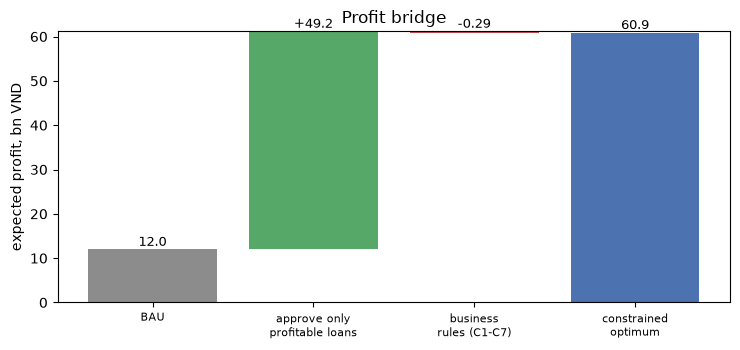

In [27]:
# --- Q5: the profit bridge BAU -> unconstrained ceiling -> constrained optimum --------------------------------
vals = {"BAU (approve all)": bau.total_portfolio, "Unconstrained ceiling": unconstrained.total_portfolio,
        "Constrained optimum": constrained.total_portfolio}
assert bau.total_portfolio <= constrained.total_portfolio <= unconstrained.total_portfolio + 1e-6      # ordering
bridge = pd.DataFrame({"expected profit (bn VND)": {k: v / 1e9 for k, v in vals.items()}})
bridge["step (bn VND)"] = bridge["expected profit (bn VND)"].diff()
bridge["multiple of BAU"] = bridge["expected profit (bn VND)"] / bridge.loc["BAU (approve all)", "expected profit (bn VND)"]
bridge["share of the ceiling"] = bridge["expected profit (bn VND)"] / bridge.loc["Unconstrained ceiling", "expected profit (bn VND)"]
display(bridge.round(3))
u, c = bridge["step (bn VND)"].iloc[1], bridge["step (bn VND)"].iloc[2]
print(f"credit policy adds {u:,.2f} bn VND ({u / bridge.iloc[0, 0]:+.0%} on BAU); the business rules then take back {-c:,.2f} bn "
      f"({-c / bridge.iloc[1, 0]:.2%} of the ceiling)")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
b0, b1, b2 = (v / 1e9 for v in vals.values())
ax.bar(0, b0, color="#8c8c8c"); ax.bar(1, b1 - b0, bottom=b0, color="#55a868"); ax.bar(2, b2 - b1, bottom=b1, color="#c44e52")
ax.bar(3, b2, color="#4c72b0")
for x, y, t in [(0, b0, f"{b0:.1f}"), (1, b1, f"+{b1 - b0:.1f}"), (2, b1, f"{b2 - b1:.2f}"), (3, b2, f"{b2:.1f}")]:
    ax.text(x, y + 0.8, t, ha="center", fontsize=9)
ax.set_xticks(range(4)); ax.set_xticklabels(["BAU", "approve only\nprofitable loans", "business\nrules (C1-C7)", "constrained\noptimum"], fontsize=8)
ax.set_ylabel("expected profit, bn VND"); ax.set_title("Profit bridge"); plt.tight_layout(); plt.show()

**Q5: the profit bridge.** BAU **11.98 bn VND** → unconstrained ceiling **61.18 bn** (+49.20 bn, **+411%**, 5.1x BAU) → constrained optimum
**60.89 bn** (-0.29 bn). Almost all of the value is the credit policy itself, i.e. *not booking the loans that destroy money*
(+49.2 bn); the seven business rules then cost **0.47% of the ceiling**, so the constrained optimum keeps **99.5%** of it and
is **5.08x** BAU. Note that the sweeps below re-solve to a 0.01% gap, which gives 60.92 bn for the same problem (section 6 solved to the
1% gap it asked for).

In [28]:
# --- Q4: what is each rule costing? Re-solve with ONE threshold moved by a small amount (full flow) ---------------
PROBES = [  # rule, parameter, current value, kind, step, unit
    ("C1 Risk rate",           "max_risk",     0.22,    "upper", 0.01,   "1 pp of the risk limit"),
    ("C2 Approval rate",       "min_approval", 0.45,    "lower", 0.01,   "1 pp of the approval floor"),
    ("C3 Funding budget",      "max_volume_m", 350_000, "upper", 10_000, "10 bn VND of budget"),
    ("C4 Long-tenor mix",      "max_long",     0.45,    "upper", 0.01,   "1 pp of the long-tenor limit"),
    ("C5 Small-ticket access", "min_micro",    0.12,    "lower", 0.01,   "1 pp of the micro floor"),
    ("C6 Pricing optics",      "max_high_ir",  0.20,    "upper", 0.01,   "1 pp of the high-IR limit"),
]
rep_b = BASE.constraint_report().set_index("constraint")
rows = []
for rule, par, v0, kind, step, unit in PROBES:
    binding = bool(rep_b.loc[rule, "binding"])
    tight = resolve(constrained, **{par: v0 - step if kind == "upper" else v0 + step})
    loose = resolve(constrained, **{par: v0 + step if kind == "upper" else v0 - step}) if binding else None
    rows.append({"rule": rule, "binding": binding, "move": unit,
                 "cost of tightening one step (bn VND)": P0 - bn(tight),
                 "gain from loosening one step (bn VND)": (bn(loose) - P0) if loose is not None else 0.0})
shadow = pd.DataFrame(rows).set_index("rule")
display(shadow.round(4))

,binding,move,cost of tightening one step (bn VND),gain from loosening one step (bn VND)
rule,,,,
C1 Risk rate,False,1 pp of the risk limit,0.0000,0.0000
C2 Approval rate,False,1 pp of the approval floor,0.0000,0.0000
C3 Funding budget,False,10 bn VND of budget,0.0000,0.0000
C4 Long-tenor mix,True,1 pp of the long-tenor limit,0.1640,0.1004
C5 Small-ticket access,True,1 pp of the micro floor,0.0471,0.0299
C6 Pricing optics,False,1 pp of the high-IR limit,0.0000,0.0000


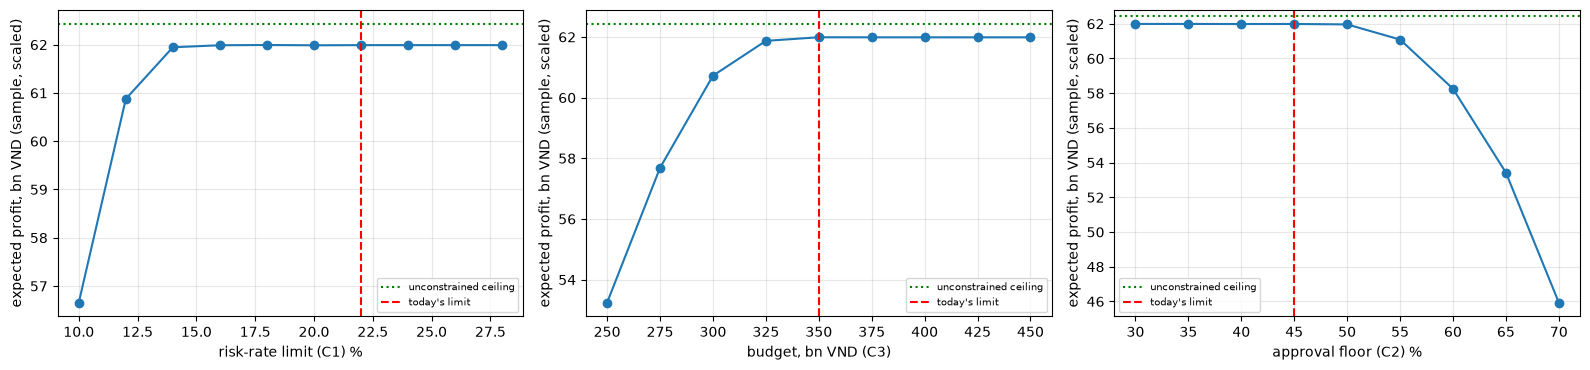

sample, scaled: ceiling 62.43 | all rules (today) 61.99 bn VND


,0.06,0.08,0.10,0.12,0.14,0.16,0.18,0.20,0.22,0.24,0.26,0.28
risk limit,NaN,NaN,56.66,60.88,61.95,61.99,61.99,61.99,61.99,61.99,61.99,61.99


In [29]:
# --- efficient frontiers (25% sample, scaled to the full portfolio) -------------------------------------------------
S = sample_run
S_ceiling = bn(S.project.scenario(name="sample ceiling", flow="unconstrained").build().optimize())
S_base = bn(resolve(S))
risk_grid = [round(x, 2) for x in np.arange(0.06, 0.2801, 0.02)]
vol_grid = list(range(250_000, 450_001, 25_000))
appr_grid = [round(x, 2) for x in np.arange(0.30, 0.7001, 0.05)]
f_risk = pd.Series({r: bn(resolve(S, max_risk=r)) for r in risk_grid})
f_vol = pd.Series({v: bn(resolve(S, max_volume_m=v)) for v in vol_grid})
f_app = pd.Series({a: bn(resolve(S, min_approval=a)) for a in appr_grid})

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, ser, x0, xl, scale in [(axes[0], f_risk, 0.22, "risk-rate limit (C1)", 100), (axes[1], f_vol, 350_000, "budget, bn VND (C3)", 1e-3),
                               (axes[2], f_app, 0.45, "approval floor (C2)", 100)]:
    ax.plot(np.array(ser.index) * scale, ser.values, marker="o")
    ax.axhline(S_ceiling, color="g", ls=":", label="unconstrained ceiling")
    ax.axvline(x0 * scale, color="r", ls="--", label="today's limit"); ax.set_xlabel(xl + (" %" if scale == 100 else ""))
    ax.set_ylabel("expected profit, bn VND (sample, scaled)"); ax.grid(alpha=.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("sample, scaled: ceiling %.2f | all rules (today) %.2f bn VND" % (S_ceiling, S_base))
display(pd.DataFrame({"risk limit": f_risk}).T.round(2))

**Q4: what is each binding rule costing (full flow, re-solved with one threshold moved)?**

| Rule | Loosen by one step | Tighten by one step |
|---|---|---|
| **C4 long-tenor limit** (+/- 1 pp) | **+0.100 bn VND** | **-0.164 bn VND** |
| **C5 micro floor** (+/- 1 pp) | **+0.030 bn VND** | **-0.047 bn VND** |
| C1 risk limit (1 pp), C2 approval floor (1 pp), C3 budget (10 bn), C6 high-IR cap (1 pp) | 0 | 0 |

The price per step is asymmetric (tightening costs more than loosening gains), the usual shape when the best swaps are made first. **The number
for the CRO: one extra percentage point of *risk appetite* is worth nothing today (0.00 bn VND); the rule that costs money is the
long-tenor cap, at about 0.10 bn VND per percentage point.**

**The efficient frontiers** (25% sample, scaled; the sample sits about 1.8% above the full run, so read the shape, not the level):

* **Risk limit (C1):** infeasible at 8% or below, 56.7 bn at 10%, 60.9 bn at 12%, 61.9 bn at 14% and flat at ~62.0 bn from 16% up. Today's 22%
  is deep inside the plateau; the limit could be cut to about 14% at essentially no cost, and only below ~12% does it start to bite.
* **Budget (C3):** flat above ~325 bn (the ceiling disburses 324 bn), 60.7 bn at 300 bn, 57.7 bn at 275 bn, 53.2 bn at 250 bn. 350 bn is on the
  plateau.
* **Approval floor (C2):** flat up to 50%, then 61.1 bn at 55%, 58.2 bn at 60%, 53.4 bn at 65% and 45.9 bn at 70%. The 45% floor is free.

In [30]:
# --- what do C5 (micro >= 12%) and C6 cost? and each rule ON ITS OWN ------------------------------------------------
full_cons = full_constraints(portfolio.data)
no_c5 = resolve(constrained, constraints=subset(full_cons, ["C1", "C2", "C3", "C4", "C6", "C7"]))
no_c6 = resolve(constrained, constraints=subset(full_cons, ["C1", "C2", "C3", "C4", "C5", "C7"]))

micro = (app.set_index("ID_APPLICATION")["PRODUCT_GROUP"] == "CLX_MICRO")
def micro_approved(sc):
    x = sc.export().set_index("ID_APPLICATION")["APPROVE_ACTION"]
    return int(x[micro.loc[x.index]].sum()), int(x.sum())
n5_with, tot_with = micro_approved(BASE)
n5_without, tot_without = micro_approved(no_c5)
cost_c5 = bn(no_c5) - P0
print(f"C5 (micro >= 12% of approvals) costs {cost_c5:,.3f} bn VND: it forces {n5_with - n5_without:+,d} micro approvals "
      f"({n5_without:,d} -> {n5_with:,d}), i.e. {cost_c5 * 1e3 / max(n5_with - n5_without, 1):,.2f} m VND of expected profit per extra micro loan")
print(f"C6 (high-IR <= 20% of approvals) costs {bn(no_c6) - P0:,.3f} bn VND (not binding)")

# each rule on its own, on the sample (the rules interact, so the single costs do not add up to the joint cost)
S_cons = full_constraints(S.project.portfolio.data)
groups = {"C1 risk": ["C1"], "C2 approval": ["C2"], "C3 budget": ["C3"], "C4 long tenor": ["C4"], "C5 micro": ["C5"],
          "C6 high IR": ["C6"], "C7 monotonicity": ["C7"]}
alone = {g: S_ceiling - bn(resolve(S, constraints=subset(S_cons, p))) for g, p in groups.items()}
alone_df = pd.DataFrame({"cost of this rule alone (bn VND)": alone})
alone_df.loc["sum of the seven"] = alone_df.sum()
alone_df.loc["all seven together"] = S_ceiling - S_base
display(alone_df.round(3))

C5 (micro >= 12% of approvals) costs 0.055 bn VND: it forces +286 micro approvals (761 -> 1,047), i.e. 0.19 m VND of expected profit per extra micro loan
C6 (high-IR <= 20% of approvals) costs 0.000 bn VND (not binding)


,cost of this rule alone (bn VND)
C1 risk,0.000
C2 approval,0.004
C3 budget,0.000
C4 long tenor,0.398
C5 micro,0.094
C6 high IR,0.000
C7 monotonicity,0.027
sum of the seven,0.524
all seven together,0.439


**What C5 and C6 cost, and whether the price is worth paying.**

* **C6 costs nothing** (0.000 bn VND): it is not binding. Either it is a harmless safeguard or it has no effect on the policy.
* **C5 costs 0.055 bn VND** (0.09% of the profit, full flow). To reach 12% micro it forces **+286 micro approvals (761 → 1,047)**, i.e.
  **0.19 m VND of expected profit per extra micro loan**. Each rule alone (sample, scaled): C4 0.40 bn, C5 0.09 bn, C7 0.03 bn, C2 0.004 bn,
  C1, C3, C6 zero; the singles add up to 0.52 bn against 0.44 bn jointly, so the rules overlap and their costs are not additive.
* **For paying the price of C5:** it is cheap (0.19 m VND per loan, 55 m VND in total on a 61 bn book), it keeps credit available in the segment
  with 20% of the applications, and micro clients may become larger borrowers later, a value this model does not capture. **Against:** micro
  is exactly where the economics are worst (median break-even PD 7.5% against a median PD of 39.5%), so every forced loan is a negative
  expected-profit loan *and* sits where the PD model is least precise. **Verdict:** pay it, because the bill is small and
  fixed; the rule worth renegotiating is **C4, which costs about seven times as much per point** (0.164 against 0.047 bn VND per 1 pp).

In [31]:
# --- the central tension, quantified: C1 (risk <= 22%) against C2 (approval >= 45%) --------------------------------
# Lowest risk rate reachable while approving >= 45% and respecting every other rule; highest approval reachable at <= 22%.
def feasible(**thr):
    return resolve(S, gap=0.05, **thr) is not None

lo, hi = 0.0, 0.22
for _ in range(10):
    mid = (lo + hi) / 2
    lo, hi = (lo, mid) if feasible(max_risk=mid) else (mid, hi)
min_risk = hi
lo, hi = 0.45, 1.0
for _ in range(10):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if feasible(min_approval=mid) else (lo, mid)
max_appr = lo
print(f"lowest risk rate reachable at >= 45% approval (all other rules kept): {min_risk:.1%}  (limit 22%, optimum uses {kpis(constrained)['C1 risk rate']:.1%})")
print(f"highest approval rate reachable at <= 22% risk (all other rules kept): {max_appr:.1%}  (floor 45%, optimum uses {kpis(constrained)['C2 approval rate']:.1%})")

lowest risk rate reachable at >= 45% approval (all other rules kept): 8.7%  (limit 22%, optimum uses 14.4%)
highest approval rate reachable at <= 22% risk (all other rules kept): 76.5%  (floor 45%, optimum uses 48.5%)


**C1 against C2, the "central tension" of the brief, is not a tension here.** Keeping the approval floor at 45% and every other rule, the
lowest risk rate that can be reached is **8.7%** (the limit is 22%, the optimum uses 14.4%). Keeping the risk limit at 22% and every other
rule, the highest approval rate that can be reached is **76.5%** (the floor is 45%, the optimum uses 48.5%). Both are far from their
thresholds, so the problem is feasible with a wide margin on this dimension. (Bisection on the 25% sample; the bounds are
about 0.1 pp precise and slightly optimistic by the sampling effect.) The tension appears only with a much worse PD, see below.

In [32]:
# --- Q3: what is the Challenge 1 model worth?  Degrade the PD (Gini -0.15), re-optimise, evaluate under the GOOD PD ----
# TARGET is used here only to MEASURE the Gini of the degraded score (that is what the brief asks for); no decision is taken on it.
def gini(y, s):
    return 2 * roc_auc_score(y, s) - 1
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
z = np.random.default_rng(7).standard_normal(len(ACTIVE))
noisy = lambda sd: 1 / (1 + np.exp(-(logit(ACTIVE["PD"].to_numpy()) + sd * z)))

g_good = gini(ACTIVE["TARGET"], ACTIVE["PD"])
lo, hi = 0.0, 6.0
for _ in range(40):                                     # noise on the logit scale, bisected until Gini = good - 0.15
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if gini(ACTIVE["TARGET"], noisy(mid)) > g_good - 0.15 else (lo, mid)
SD = (lo + hi) / 2
app_noisy = ACTIVE.copy()
app_noisy["PD"] = noisy(SD)
app_noisy["RISK_BAND"] = pd.cut(app_noisy["PD"], PD_BINS, labels=False, right=False).astype(int)
g_noisy = gini(app_noisy["TARGET"], app_noisy["PD"])
print(f"noise sd on the logit scale {SD:.2f}: Gini {g_good:.3f} -> {g_noisy:.3f} (mean PD {ACTIVE['PD'].mean():.3f} -> {app_noisy['PD'].mean():.3f})")

p_noisy = make_project(app_noisy, 1.0, name="degraded PD")
cons_noisy = full_constraints(p_noisy.portfolio.data)
sc_noisy = p_noisy.scenario(name="degraded PD", flow="constrained", constraints=cons_noisy).build().optimize(time_limit=600, gap=1e-3)

true = app.set_index("ID_APPLICATION")
def describe(sc, label, gini_value, believed):
    x = sc.export().set_index("ID_APPLICATION")["APPROVE_ACTION"]
    amt = true.loc[x.index, "AMOUNT_VND"] * x
    rep_ = sc.constraint_report()
    return {"Gini of the PD used": gini_value,
            "profit the optimiser believes (bn VND)": believed,
            "expected profit under the GOOD PD (bn VND)": policy_value(x),
            "approval rate": float(x.mean()),
            "risk rate under the GOOD PD": float((true.loc[x.index, "PD"] * amt).sum() / amt.sum()),
            "volume (bn VND)": float(amt.sum() / 1e9 * portfolio.scale),
            "binding (non-trivial, C1-C6)": ", ".join(g.split()[0] for g in nontrivial_binding(rep_) if not g.startswith("C7"))}
cmp_pd = pd.DataFrame({"Challenge 1 PD": describe(BASE, "good", g_good, P0),
                       "degraded PD": describe(sc_noisy, "noisy", g_noisy, bn_active(sc_noisy))})
display(cmp_pd)
worth = cmp_pd.loc["expected profit under the GOOD PD (bn VND)", "Challenge 1 PD"] - cmp_pd.loc["expected profit under the GOOD PD (bn VND)", "degraded PD"]
print(f"value of the better PD model: {worth:,.2f} bn VND of expected profit on the May-2015 flow "
      f"({worth / P0:.1%} of the constrained optimum; {worth * 12:,.1f} bn VND per year at a constant monthly flow)")

noise sd on the logit scale 1.39: Gini 0.701 -> 0.551 (mean PD 0.360 -> 0.377)


,Challenge 1 PD,degraded PD
Gini of the PD used,0.701441,0.551441
profit the optimiser believes (bn VND),60.924276,62.137502
expected profit under the GOOD PD (bn VND),60.924276,50.524015
approval rate,0.485258,0.465176
risk rate under the GOOD PD,0.144404,0.177825
volume (bn VND),335.513,318.9354
"binding (non-trivial, C1-C6)","C4, C5","C4, C5"


value of the better PD model: 10.40 bn VND of expected profit on the May-2015 flow (17.1% of the constrained optimum; 124.8 bn VND per year at a constant monthly flow)


**Q3: what is the Challenge 1 model worth?** Logit noise with sd 1.39 brings the Gini from **0.701 to 0.551** (mean PD 0.360 → 0.377). TARGET is
used here only to *measure* that Gini; no decision is taken on it. The optimisation is repeated on the degraded PD and the resulting
policy is then **evaluated under the Challenge 1 PD** (expected values, no outcomes):

* the degraded policy *believes* it earns **62.14 bn VND** but earns **50.52 bn** under the good PD, an **illusion of 11.6 bn** (the winner's
  curse: it picks the loans whose noise happens to look attractive), while the good-PD policy earns what it expects (60.92 bn);
* **the value of the Challenge 1 model is 10.40 bn VND of expected profit on the May-2015 flow, 17.1% of the constrained optimum**
  (about 125 bn VND per year if the monthly flow repeated, an assumption);
* the degraded policy approves less (46.5% against 48.5%) and disburses less (319 bn against 336 bn);
* **the binding set does not move:** C4 and C5 in both. The brief expects a sharper model to push the risk rule off its boundary, but C1 is
  already slack with the good model (14.4%) and stays slack under the weak one (17.8% evaluated with the good PD, still below 22%). The
  model's worth shows in profit, not in which rule binds. Caveat: "worth" assumes the Challenge 1 PD is closer to the truth than
  the degraded one; the realised check against `TARGET` is the back-test of section 9.

In [33]:
# --- sensitivity of the profit assumptions: recovery rate (10 / 30%) and default timing (25 / 50% of the tenor) ------
def solve_facts(**changes):
    f = project.facts.copy()
    for k, v in changes.items():
        f.set(k, v, "sensitivity run")
    p = make_project(ACTIVE, 1.0, facts=f, name=str(changes))
    return p.scenario(name=str(changes), flow="constrained", constraints=full_constraints(p.portfolio.data)).build().optimize(time_limit=600, gap=1e-3)

x_base = BASE.export().set_index("ID_APPLICATION")["APPROVE_ACTION"]
sens = {"base: recovery 20%, default at 35%": BASE}
for label, kw in [("recovery 10%", dict(recovery_rate=0.10)), ("recovery 30%", dict(recovery_rate=0.30)),
                  ("default at 25% of tenor", dict(default_at=0.25)), ("default at 50% of tenor", dict(default_at=0.50))]:
    sens[label] = solve_facts(**kw)

rows = {}
for label, sc in sens.items():
    x = sc.export().set_index("ID_APPLICATION")["APPROVE_ACTION"]
    rows[label] = {"profit, own assumptions (bn VND)": bn_active(sc), "approval rate": float(x.mean()),
                   "decisions that differ from the base policy": float((x.reindex(x_base.index) != x_base).mean()),
                   "regret under the base assumptions (bn VND)": P0 - policy_value(x),
                   "binding (non-trivial, C1-C6)": ", ".join(g.split()[0] for g in nontrivial_binding(sc.constraint_report()) if not g.startswith("C7"))}
display(pd.DataFrame(rows).T)

,"profit, own assumptions (bn VND)",approval rate,decisions that differ from the base policy,regret under the base assumptions (bn VND),"binding (non-trivial, C1-C6)"
"base: recovery 20%, default at 35%",60.924276,0.485258,0.0,0.0,"C4, C5"
recovery 10%,57.507542,0.462561,0.023031,0.213186,"C4, C5"
recovery 30%,64.825753,0.506064,0.022474,0.205929,"C3, C4, C5"
default at 25% of tenor,56.144538,0.452826,0.032543,0.438374,"C4, C5"
default at 50% of tenor,70.827173,0.502448,0.044226,0.804236,"C3, C4, C5"


**Sensitivity of the profit assumptions (full flow).** The optimal policy is **stable**; the profit level is not.

| Assumption | Profit (own assumptions) | Approval | Decisions that change | Regret under the base assumptions |
|---|---|---|---|---|
| base: recovery 20%, default at 35% | 60.92 bn | 48.5% | - | - |
| recovery 10% | 57.51 bn | 46.3% | 2.3% | 0.21 bn |
| recovery 30% | 64.83 bn | 50.6% | 2.2% | 0.21 bn |
| default at 25% of the tenor | 56.14 bn | 45.3% | 3.3% | 0.44 bn |
| default at 50% of the tenor | 70.83 bn | 50.2% | 4.4% | 0.80 bn |

Moving recovery by 10 pp changes **about 2% of the decisions** and costs 0.21 bn of regret (0.3% of the profit), so the policy is shippable with respect
to recovery. Default timing matters more (up to 4.4% of decisions and 0.80 bn of regret, 1.3%), and it is the assumption to firm up first. The
binding set is always C4 and C5; **C3 (the budget) joins when the assumptions make loans more profitable** (recovery 30%, default at 50%): more
loans pay, so the budget starts to bind. With default at 25% the approval rate (45.3%) comes within 0.3 pp of the C2 floor.

### Summary of the diagnostics

1. **Binding rules:** C4 and C5. **Slack:** C1, C3, C6 (the profit objective already stays inside them) and C2 (C5 pushes approvals above what profit needs).
2. **Value of the Challenge 1 PD:** **10.4 bn VND** of expected profit on this month (17%), and a degraded score would also make the optimiser overstate its profit by 11.6 bn.
3. **Shadow prices:** one more point of long-tenor limit is worth **0.10 bn VND**, of the micro floor 0.03 bn; **risk appetite, approval floor, budget and the pricing cap are worth 0.**
4. **Profit bridge:** 11.98 → 61.18 → 60.89 bn VND; the credit policy is the value, the rules cost 0.47% of the ceiling.
5. **Robust:** the policy moves by 2-4% of the decisions under realistic changes of recovery and default timing.

Caveats: the sweeps (frontiers, single-rule costs, bisections) run on a 25% sample and overstate levels by about 1.8%; every value is an
*expected* value under the Challenge 1 PD and the synthetic economics of the brief; the realised check is the back-test of section 9.

## 8. Distil the solution into a deployable policy

PyDO has just given you an optimal decision for each of ~18,000 individual applications. **That is
not a policy.** Nobody can deploy it, audit it, or explain it to a branch manager, and it will not
generalise to next month's applications.

`do.DecisionTree` solves this: it fits a CART over **raw portfolio fields** to the optimized
decisions, and — because your source scenario is `constrained` — it then **re-optimizes one shared
action per leaf** against the same constraints. The result is a small set of business rules that is
still feasible.

This is your actual deliverable: a risk-band policy a human can read.

In [34]:
# --- 8.0 How many rules does the policy need?  Grow trees of increasing size and price each one -----------------------
# The source is the account-level optimum solved to a 0.01% gap (BASE, section 7b): the tree is judged against the real optimum,
# not against a solution that is itself up to 1% away from it. The leaf-level re-optimisation is tiny, so it is solved to a 0.01% gap too.
SOURCE = project.register(BASE, "Constrained policy")           # the 0.01%-gap solve is THE constrained policy in every report below
candidate_features = [
    "RISK_BAND",
    "PRODUCT_GROUP",
    "TENOR_BUCKET",
    "AMOUNT_M",
    "INTEREST_RATE",
]
src_profit = bn(SOURCE)

def try_tree(features, max_depth, max_splits, min_gini_gain=0.0001, min_weight=100):
    t = do.DecisionTree(max_depth=max_depth, max_splits=max_splits, min_weight=min_weight, min_gini_gain=min_gini_gain)
    try:
        t.fit(scenario=SOURCE, variables=features, solver="highs", time_limit=300, gap=1e-4, constrained_growth="posthoc")
    except do.InfeasibleModelError:
        return None
    return t

rows = []
# min_gini_gain is part of the grid: the template's 0.0001 stops the CART from ever splitting on PRODUCT_GROUP, the very
# dimension on which C5 (micro quota) and C7 (monotonicity per product) are written.
for depth, splits, gain in [(3, 7, 1e-4), (4, 15, 1e-4), (6, 31, 1e-4), (4, 15, 0.0), (5, 31, 0.0), (6, 31, 0.0), (6, 63, 0.0), (7, 63, 0.0)]:
    t = try_tree(candidate_features, depth, splits, gain)
    if t is None:
        rows.append({"max_depth": depth, "max_splits": splits, "min_gini_gain": gain, "leaves": np.nan, "feasible": False})
        continue
    perf = t.performance()
    rows.append({"max_depth": depth, "max_splits": splits, "min_gini_gain": gain, "leaves": t.n_leaves, "feasible": True,
                 "expected profit (bn VND)": bn_active(t.policy_), "cost vs account-level (bn VND)": src_profit - bn_active(t.policy_),
                 "% of account-level optimum": bn_active(t.policy_) / src_profit,
                 "agreement (train)": perf.loc["train", "agreement with account-level policy"],
                 "agreement (test)": perf.loc["test", "agreement with account-level policy"],
                 "predictors used": ", ".join(t.selected_features)})
grid = pd.DataFrame(rows)
display(grid.round(4))

# the rule, written down BEFORE looking at the final tree: the smallest feasible tree whose deployability cost is at most 3% of the
# account-level optimum (a policy a risk committee can read in one page, within a few percent of the solver's answer)
ok = grid[(grid["feasible"]) & (grid["% of account-level optimum"] >= 0.97)]
chosen = ok.sort_values(["leaves", "max_depth"]).iloc[0] if len(ok) else grid[grid["feasible"]].sort_values("% of account-level optimum").iloc[-1]
TREE_CFG = dict(max_depth=int(chosen["max_depth"]), max_splits=int(chosen["max_splits"]), min_gini_gain=float(chosen["min_gini_gain"]))
print("chosen:", TREE_CFG, f"-> {int(chosen['leaves'])} leaves, {chosen['% of account-level optimum']:.2%} of the account-level optimum")

# is PD itself a better predictor than the banded RISK_BAND?  Same size, same rule, PD offered instead of the band.
alt = try_tree(["PD", "PRODUCT_GROUP", "TENOR_BUCKET", "AMOUNT_M", "INTEREST_RATE"], **TREE_CFG)
print("with PD instead of RISK_BAND:", "infeasible" if alt is None else
      f"{alt.n_leaves} leaves, {bn_active(alt.policy_) / src_profit:.2%} of the optimum, predictors {alt.selected_features}")

,max_depth,max_splits,min_gini_gain,leaves,feasible,expected profit (bn VND),cost vs account-level (bn VND),% of account-level optimum,agreement (train),agreement (test),predictors used
0,3,7,0.0001,7,True,53.3983,7.5260,0.8765,0.8426,0.8365,"RISK_BAND, TENOR_BUCKET"
1,4,15,0.0001,11,True,53.3983,7.5260,0.8765,0.8426,0.8365,"RISK_BAND, TENOR_BUCKET, INTEREST_RATE"
2,6,31,0.0001,17,True,55.7308,5.1935,0.9148,0.8477,0.8389,"RISK_BAND, TENOR_BUCKET, AMOUNT_M, INTEREST_RATE"
3,4,15,0.0000,16,True,53.3983,7.5260,0.8765,0.8426,0.8365,"RISK_BAND, TENOR_BUCKET, INTEREST_RATE"
4,5,31,0.0000,27,True,55.2215,5.7028,0.9064,0.8972,0.8899,"RISK_BAND, TENOR_BUCKET, INTEREST_RATE"
5,6,31,0.0000,32,True,59.3104,1.6138,0.9735,0.9293,0.9214,"RISK_BAND, PRODUCT_GROUP, TENOR_BUCKET, AMOUNT..."
6,6,63,0.0000,37,True,59.3104,1.6138,0.9735,0.9293,0.9214,"RISK_BAND, PRODUCT_GROUP, TENOR_BUCKET, AMOUNT..."
7,7,63,0.0000,45,True,59.3104,1.6138,0.9735,0.9293,0.9214,"RISK_BAND, PRODUCT_GROUP, TENOR_BUCKET, AMOUNT..."


chosen: {'max_depth': 6, 'max_splits': 31, 'min_gini_gain': 0.0} -> 32 leaves, 97.35% of the account-level optimum
with PD instead of RISK_BAND: 32 leaves, 97.42% of the optimum, predictors ['PD', 'TENOR_BUCKET', 'AMOUNT_M', 'INTEREST_RATE']


**How many rules does the policy need?** The size of the tree is a trade-off, and the grid prices it:

| Tree | Leaves | Expected profit | Kept from the account-level optimum |
|---|---|---|---|
| depth 4, template gain threshold | 11 | 53.40 bn | 87.7% |
| depth 6, template gain threshold | 17 | 55.73 bn | 91.5% |
| depth 5, gain threshold 0 | 27 | 55.22 bn | 90.6% |
| **depth 6, gain threshold 0 (chosen)** | **32** | **59.31 bn** | **97.35%** |

The template's `min_gini_gain = 0.0001` is what holds the small trees back: with it the CART never splits on `PRODUCT_GROUP`, the very
dimension on which C5 (the micro quota) and C7 (monotonicity per product) are written, so the leaves cannot be shaped to satisfy them
cheaply, and the cost stays around 9-12% of the profit. With the threshold at 0 the product split appears and the cost falls to 2.65%.
The size rule was written down before looking at the result: *the smallest feasible tree whose deployability cost is at most 3%*,
which picks 32 leaves. That is a policy **table**, not "a handful" of rules; the 17-leaf tree is the readable alternative at a price of 5.2 bn VND
(8.5%). Offering the continuous `PD` instead of the band gives 97.42% against 97.35%: no better, and a fixed-band rule is easier to deploy and monitor.

In [35]:
tree = do.DecisionTree(
    max_depth=TREE_CFG["max_depth"],     # chosen in 8.0: the smallest tree that keeps >= 97% of the account-level optimum
    max_splits=TREE_CFG["max_splits"],
    min_weight=100,                      # minimum accounts per branch
    min_gini_gain=TREE_CFG["min_gini_gain"],
)

tree.fit(
    scenario=SOURCE,
    variables=candidate_features,
    n_jobs=-1,
    solver="highs",
    time_limit=300,
    gap=1e-4,                            # the leaf problem is tiny: solve it to optimality (the template's 5% would blur the cost)
    constrained_growth="posthoc",
)
print(tree)

DecisionTree(32 leaves, predictors ['RISK_BAND', 'PRODUCT_GROUP', 'TENOR_BUCKET', 'AMOUNT_M', 'INTEREST_RATE'])


### Reading the distilled tree

A fitted tree is not a result until you have read it. PyDO gives you a specific set of
inspection surfaces — use them in this order, because each one answers a different question.

| Call | The question it answers |
|---|---|
| `tree.selected_features` vs `tree.attempted_features` | Which predictors survived? |
| `tree.rules_` | What are the actual business rules, leaf by leaf? |
| `tree.visualize()` | Does the shape make sense to a human? |
| `tree.performance()` | Does it hold up on test / OOT, or only on train? |
| `tree.objective_report()` | **What did deployability cost?** |
| `tree.explain()` | Which predictors drive the policy, and in which direction? |

The one that gets graded hardest is `objective_report()`. It compares the source account-level
policy against the final tree policy — that difference is the price you paid to turn 18,000
individual decisions into a handful of rules, and you must state it in VND rather than hide it.

offered : ['RISK_BAND', 'PRODUCT_GROUP', 'TENOR_BUCKET', 'AMOUNT_M', 'INTEREST_RATE']
selected: ['RISK_BAND', 'PRODUCT_GROUP', 'TENOR_BUCKET', 'AMOUNT_M', 'INTEREST_RATE']
ignored : []
[leaf  0] IF RISK_BAND = 6 AND TENOR_BUCKET = 'T_LONG'  THEN action = 1   (234 accounts)
[leaf  1] IF 7 <= RISK_BAND <= 8 AND TENOR_BUCKET = 'T_LONG' AND INTEREST_RATE <= 0.2886  THEN action = 0   (209 accounts)
[leaf  2] IF RISK_BAND = 6 AND TENOR_BUCKET = 'T_MID' AND AMOUNT_M <= 28 AND INTEREST_RATE > 0.32865  THEN action = 1   (219 accounts)
[leaf  3] IF RISK_BAND = 6 AND TENOR_BUCKET = 'T_MID' AND AMOUNT_M > 28 AND INTEREST_RATE > 0.32865  THEN action = 1   (141 accounts)
[leaf  4] IF RISK_BAND = 7 AND TENOR_BUCKET = 'T_LONG' AND INTEREST_RATE > 0.2886  THEN action = 1   (133 accounts)
[leaf  5] IF RISK_BAND = 8 AND TENOR_BUCKET = 'T_LONG' AND INTEREST_RATE > 0.2886  THEN action = 1   (171 accounts)
[leaf  6] IF RISK_BAND = 5 AND TENOR_BUCKET = 'T_LONG'  THEN action = 1   (250 accounts)
[leaf  7] IF 

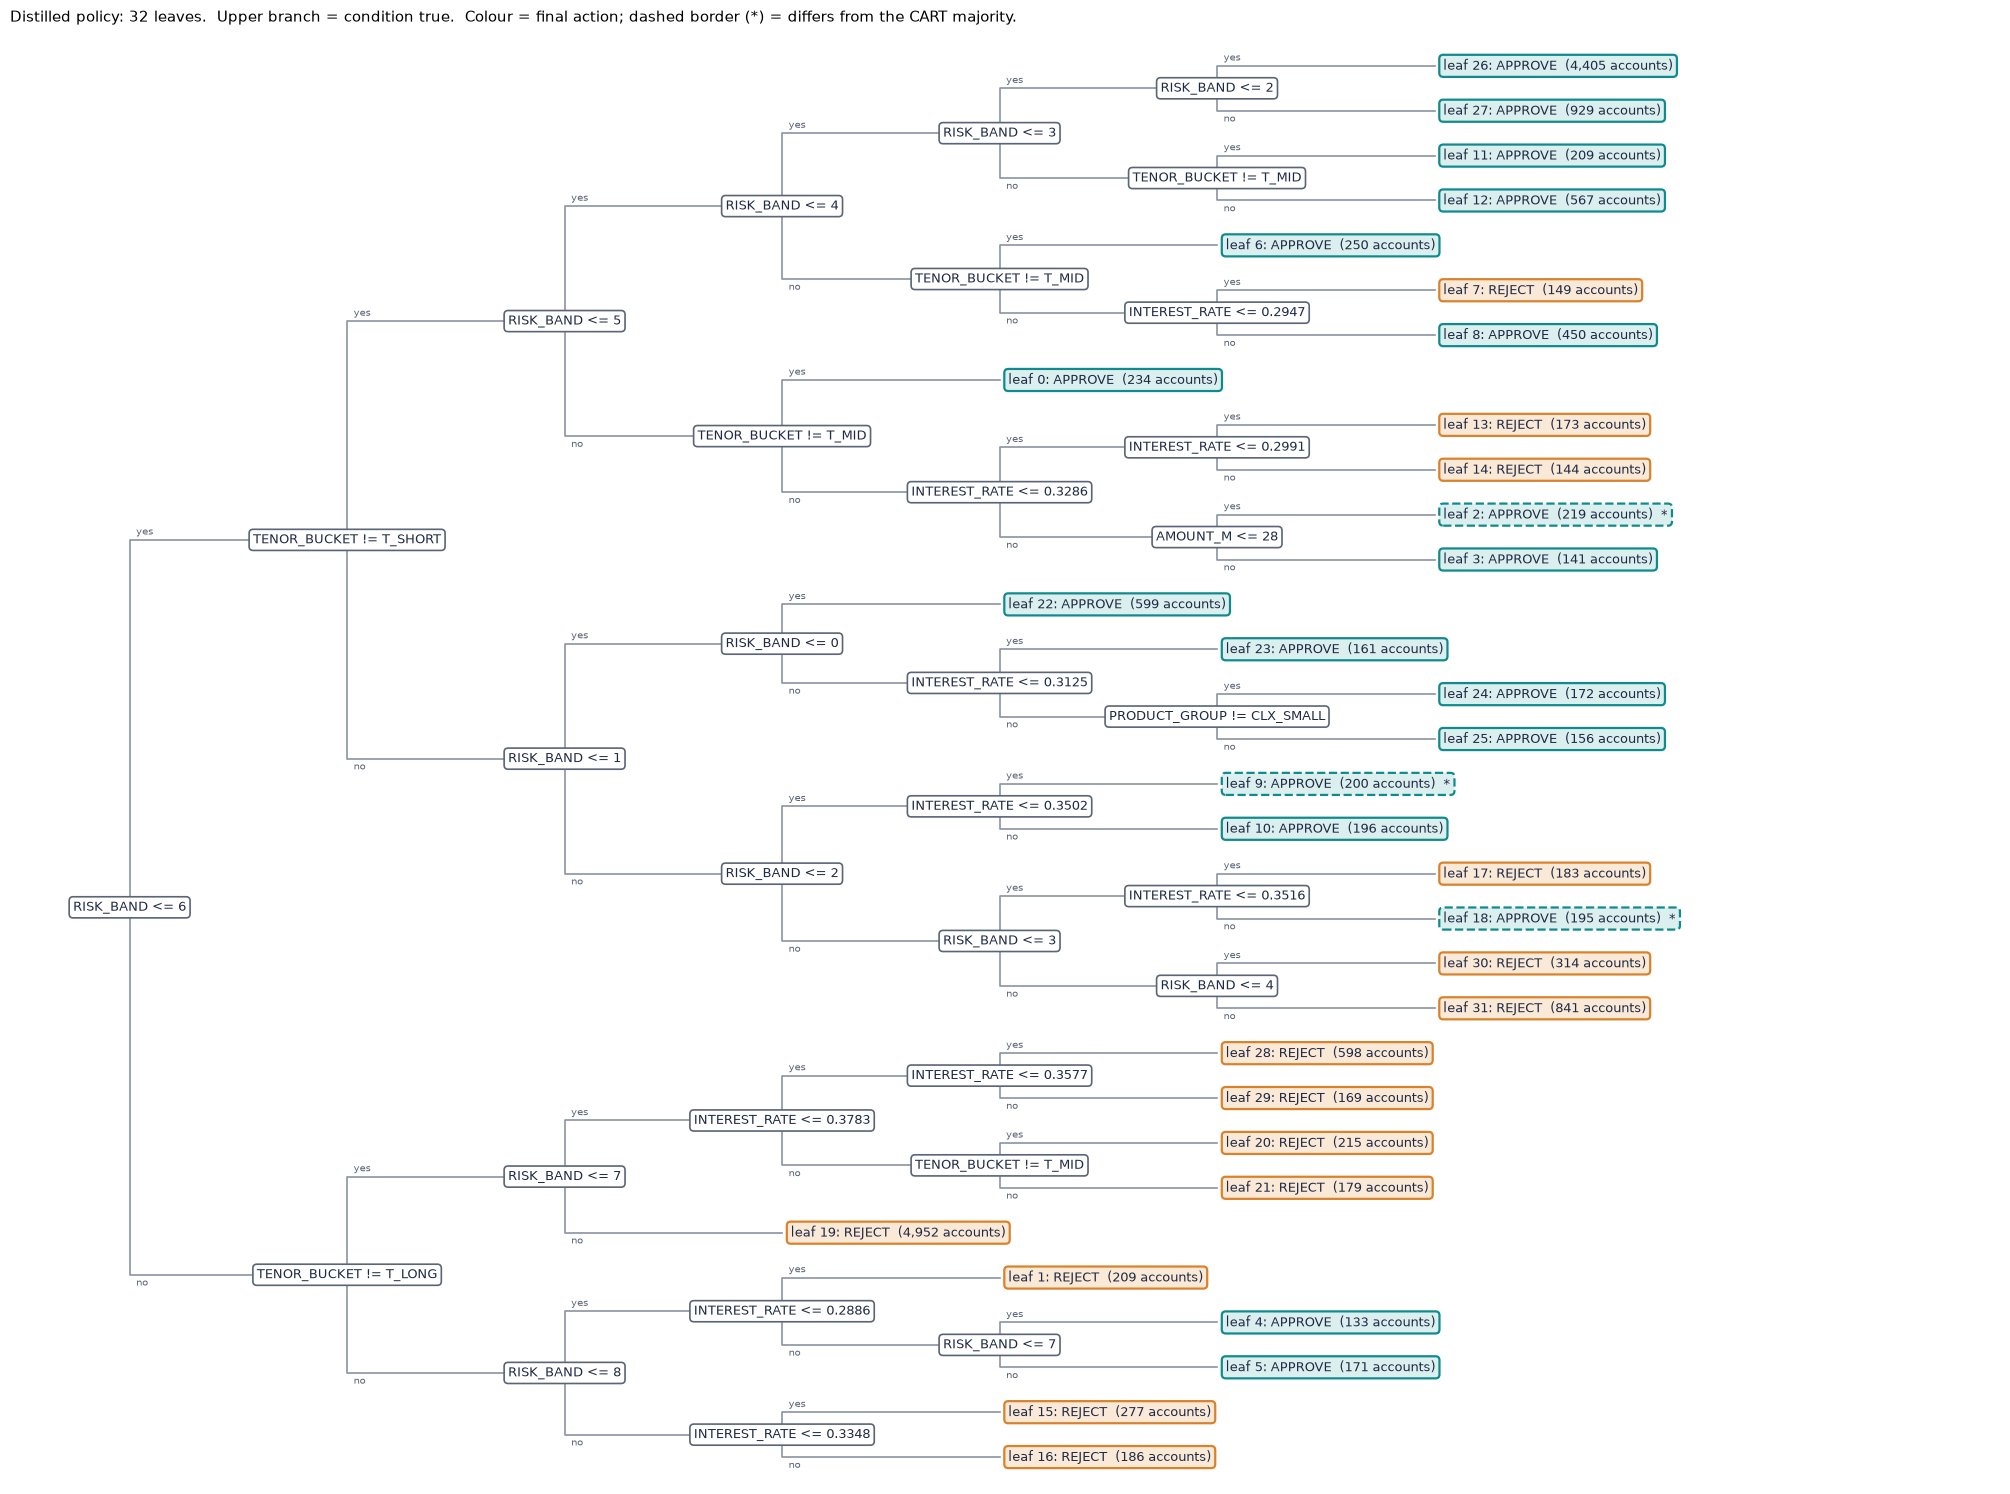

In [36]:
# --- 1. What did the tree actually use? ---------------------------------------
print("offered :", tree.attempted_features)
print("selected:", tree.selected_features)
print("ignored :", [f for f in tree.attempted_features if f not in tree.selected_features])
# A predictor you offered and the tree ignored is information: it was redundant given the others,
# or it never separated the decision. Say which, do not just list them.

# --- 2. The policy itself, leaf by leaf ---------------------------------------
# rules_ carries one readable rule and one action per terminal leaf -- this IS the deliverable.
for rule in tree.rules_:
    print(rule)

fig = tree.visualize()
plt.show()

In [37]:
# --- 3. Does it hold up, and what did it cost? --------------------------------
display(tree.performance())          # train / test (no out-of-time sample exists: only May carries a PD) -- a tree that only works on train is not a policy
tree.print_objectives()

objective_comparison = tree.objective_report()
display(objective_comparison)

cost_bn = objective_comparison.iloc[0, 0] - objective_comparison.iloc[2, 0]
print(f"\nsimplifying 17,976 account decisions to {tree.n_leaves} rules cost {cost_bn:.3f} bn VND, "
      f"which is {cost_bn / objective_comparison.iloc[0, 0]:.2%} of the account-level optimum.")

# is the loss concentrated in one leaf?
leaf_tbl = tree.leaves_.sort_values("loss_vs_source_bn", ascending=False)
leaf_tbl["share of the loss"] = leaf_tbl["loss_vs_source_bn"] / leaf_tbl["loss_vs_source_bn"].sum()
display(leaf_tbl[["rule", "action", "accounts", "source_approval_share", "loss_vs_source_bn", "share of the loss"]].round(4))

,accounts,agreement with account-level policy,"approval rate, account-level","approval rate, tree",profit kept vs account-level
train,12583.0,0.92927,0.484702,0.522530,0.975530
test,5393.0,0.92138,0.486557,0.521417,0.968722


32 leaves from 5 predictors ['RISK_BAND', 'PRODUCT_GROUP', 'TENOR_BUCKET', 'AMOUNT_M', 'INTEREST_RATE']
  account-level optimum (source scenario)                       60.924 bn VND  (100.00% of the optimum) | rules violated: 0
  tree, majority action per leaf (before re-optimisation)       59.663 bn VND  (97.93% of the optimum) | rules violated: 3
  distilled tree (leaf actions re-optimised)                    59.310 bn VND  (97.35% of the optimum) | rules violated: 0
=> simplifying 17,976 account decisions into 32 rules cost 1.614 bn VND, 2.65% of the account-level optimum


,expected profit (bn VND),rules violated,vs account-level (bn VND),% of account-level optimum
account-level optimum (source scenario),60.924276,0.0,0.000000,1.000000
"tree, majority action per leaf (before re-optimisation)",59.663207,3.0,-1.261068,0.979301
distilled tree (leaf actions re-optimised),59.310449,0.0,-1.613827,0.973511



simplifying 17,976 account decisions to 32 rules cost 1.614 bn VND, which is 2.65% of the account-level optimum.


,rule,action,accounts,source_approval_share,loss_vs_source_bn,share of the loss
leaf,,,,,,
1,7 <= RISK_BAND <= 8 AND TENOR_BUCKET = 'T_LONG...,reject,209,0.2153,0.2439,0.1511
2,RISK_BAND = 6 AND TENOR_BUCKET = 'T_MID' AND A...,approve,219,0.3607,0.1957,0.1213
8,RISK_BAND = 5 AND TENOR_BUCKET = 'T_MID' AND I...,approve,450,0.6978,0.1583,0.0981
5,RISK_BAND = 8 AND TENOR_BUCKET = 'T_LONG' AND ...,approve,171,0.4795,0.1568,0.0972
3,RISK_BAND = 6 AND TENOR_BUCKET = 'T_MID' AND A...,approve,141,0.6879,0.1177,0.0730
12,RISK_BAND = 4 AND TENOR_BUCKET = 'T_MID',approve,567,0.8166,0.1094,0.0678
18,RISK_BAND = 3 AND TENOR_BUCKET = 'T_SHORT' AND...,approve,195,0.3641,0.1076,0.0667
16,RISK_BAND >= 9 AND TENOR_BUCKET = 'T_LONG' AND...,reject,186,0.1075,0.1001,0.0620
9,RISK_BAND = 2 AND TENOR_BUCKET = 'T_SHORT' AND...,approve,200,0.4200,0.0922,0.0571


**What deployability cost.** *Simplifying 17,976 account decisions into 32 rules cost 1.61 bn VND, which is 2.65% of the account-level optimum*
(59.31 bn against 60.92 bn).

* **Re-optimising the leaf actions matters.** Taking the CART's majority action per leaf would keep 59.66 bn (97.9%) but **violates 3 of the 42 rules**;
  re-optimising one action per leaf against the same constraints costs a further 0.35 bn and leaves **no rule violated**.
* **The loss is spread, not concentrated.** The worst leaf accounts for 15% of the loss and the five worst for about 54%; there is no single branch where a deeper
  tree would buy most of it back.
* **It is not memorised.** Agreement with the account-level policy is 92.9% on the accounts the CART was grown on and 92.1% on accounts it never saw, and the
  tree keeps 97.6% / 96.9% of the account-level profit on them. A caveat: only May 2015 carries a PD, so there is no out-of-time sample; this is a random split of accounts.

<venv>\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


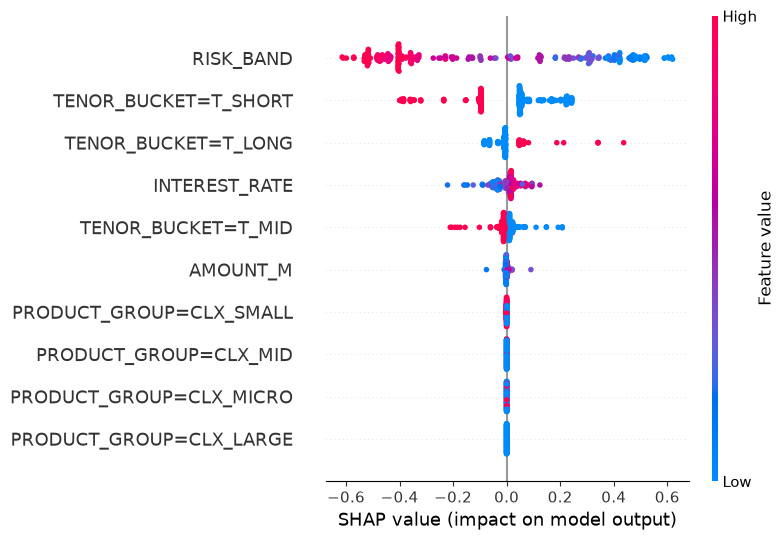

RISK_BAND                  0.3692
TENOR_BUCKET=T_SHORT       0.1295
TENOR_BUCKET=T_LONG        0.0328
INTEREST_RATE              0.0288
TENOR_BUCKET=T_MID         0.0256
AMOUNT_M                   0.0032
PRODUCT_GROUP=CLX_SMALL    0.0005
PRODUCT_GROUP=CLX_LARGE    0.0000
PRODUCT_GROUP=CLX_MICRO    0.0000
PRODUCT_GROUP=CLX_MID      0.0000
dtype: float64

corr(approve, RISK_BAND) = -0.83
corr(approve, AMOUNT_M) = +0.23
corr(approve, INTEREST_RATE) = -0.35
approval rate by product: {'CLX_LARGE': 0.771, 'CLX_MICRO': 0.335, 'CLX_MID': 0.685, 'CLX_SMALL': 0.512}
approval rate by tenor  : {'T_LONG': 0.805, 'T_MID': 0.567, 'T_SHORT': 0.289}


In [38]:
# --- 4. Which predictors drive the policy? ------------------------------------
# SHAP is computed only over the SELECTED features -- ignored predictors are not in the masker.
figures = tree.explain(
    plot_type="beeswarm",
    max_background=100,
    max_samples=250,
)
plt.show()
display(figures["mean_abs_shap"].round(4))

# direction check against the economics of section 2: does a riskier / smaller / shorter loan push towards REJECT?
chk = app.set_index("ID_APPLICATION").loc[tree.policy_.export()["ID_APPLICATION"]].assign(
    approve=tree.policy_.export()["APPROVE_ACTION"].to_numpy())
for f in [c for c in ["RISK_BAND", "AMOUNT_M", "INTEREST_RATE"] if c in tree.selected_features]:
    corr = np.corrcoef(chk[f].to_numpy(float), chk["approve"].to_numpy(float))[0, 1]
    print(f"corr(approve, {f}) = {corr:+.2f}")
print("approval rate by product:", chk.groupby("PRODUCT_GROUP")["approve"].mean().round(3).to_dict())
print("approval rate by tenor  :", chk.groupby("TENOR_BUCKET")["approve"].mean().round(3).to_dict())

**Do the drivers push in the direction the economics of section 2 predict? Yes.**

* **`RISK_BAND` dominates** (mean |SHAP| 0.37; correlation with the approval -0.83): riskier means more likely rejected.
* **Tenor:** short tenors push towards rejection (approval rate 29% for `T_SHORT`, 57% for `T_MID`, 81% for `T_LONG`), which is the fixed-cost effect of section 2b: a
  short loan cannot earn enough interest to pay for the acquisition and servicing cost, nor to absorb a default.
* **Ticket (`AMOUNT_M`):** small influence, but the sign is right (correlation +0.23: bigger loans are approved more, because the fixed costs are diluted).
* **`INTEREST_RATE`:** the raw correlation with the approval is -0.35, which looks backwards but is confounded (high rates go with high PD). *Inside* a risk band and a
  tenor the leaves approve when the rate is above a threshold and reject below it (e.g. leaves 4, 5, 8 vs 1, 7), exactly as a rate that compensates the risk should.
* **`PRODUCT_GROUP`** has almost no SHAP weight (0.0005) and enters through a single split (`CLX_SMALL`); product is mostly carried by tenor, ticket and rate. It is
  still needed in the partition: without it the cost jumps (section 8.0).

No driver pushes the wrong way, so there is no sign of a data problem or a profit-model bug.

In [39]:
# --- 5. Does the distilled policy still satisfy C1-C7? ------------------------------------------------------
# Never assume it does: score it the way everything else was scored (the same evaluator, constraint_report()), next to the baselines.
tree_decisions = tree.predict(portfolio.data)
policy = tree.policy_

# a one-dimensional benchmark: the single PD cut-off that earns the most expected profit (no product / tenor awareness)
pd_col = portfolio.data["PD"].to_numpy()
cuts = np.quantile(pd_col, np.linspace(0.25, 0.85, 61))
cut_profit = [bn(SOURCE.apply_policy((pd_col <= c).astype(int), name="_cut")) for c in cuts]
CUT = float(cuts[int(np.argmax(cut_profit))])
cutoff = SOURCE.apply_policy((pd_col <= CUT).astype(int), name="Single PD cut-off")

def evaluate_policy(scen):
    """The six constraint KPIs, the expected profit and the number of rules violated (the SAME evaluator for every policy)."""
    k = kpis(scen)
    rep_ = scen.constraint_report()
    k["rules violated (of %d)" % len(rep_)] = int((~rep_["satisfied"]).sum())
    return k

pols = {"BAU (approve all)": bau, "Single PD cut-off": cutoff, "Unconstrained": unconstrained,
        "Constrained (account level)": SOURCE, "Distilled tree": policy}
eval_tbl = pd.DataFrame({n: evaluate_policy(s) for n, s in pols.items()})
for k, (op, thr) in THRESHOLDS.items():
    eval_tbl.loc[k, "limit"] = f"{op} {thr}"
display(eval_tbl.round(4))
print(f"single PD cut-off chosen: PD <= {CUT:.3f}")

assert policy.constraint_report()["satisfied"].all(), "the distilled policy violates a rule"
print("every one of the", len(policy.constraint_report()), "rules is satisfied by the distilled policy")

,BAU (approve all),Single PD cut-off,Unconstrained,Constrained (account level),Distilled tree,limit
C1 risk rate,0.3285,0.1351,0.1462,0.1444,0.1462,<= 0.22
C2 approval rate,1.0000,0.5700,0.4443,0.4853,0.5222,>= 0.45
C3 volume (bn VND),574.3773,354.2499,324.4531,335.5130,347.6174,<= 350.0
C4 long-tenor share,0.3328,0.3787,0.4787,0.4500,0.4458,<= 0.45
C5 micro share,0.2013,0.1655,0.0715,0.1200,0.1293,>= 0.12
C6 high-IR share,0.1799,0.0955,0.0769,0.0861,0.0846,<= 0.2
expected profit (bn VND),11.9781,54.9425,61.1794,60.9243,59.3104,NaN
rules violated (of 42),2.0000,1.0000,4.0000,0.0000,0.0000,NaN


single PD cut-off chosen: PD <= 0.362
every one of the 42 rules is satisfied by the distilled policy


**The five policies, scored by the same evaluator (`constraint_report()` and the same KPI code).**

* The **distilled tree satisfies all 42 rules** and earns **59.31 bn VND**, 97.35% of the account-level optimum and 5.0x BAU (11.98 bn).
* The **best single PD cut-off** (PD <= 0.362, no product or tenor awareness) earns 54.94 bn (90% of the optimum) and breaks the budget rule (354 bn against 350 bn): knowing the product,
  tenor and rate is worth about 4.4 bn VND over a plain score cut-off.
* The tree approves more than the account-level solution (52.2% against 48.5%) and uses the budget almost fully: **volume 347.6 bn against the 350 bn limit, and the long-tenor
  share 44.6% against 45%**. It is feasible but with less headroom than the account-level optimum, because it has to decide whole leaves; if the application mix moves the
  policy must be re-optimised before it is trusted.

In [40]:
# --- 6. Save and hand over ----------------------------------------------------
model_path = tree.save("../results/models/clx_approval_tree.json", overwrite=True)

# `pydo` has no FICO exporter (proprietary decision-tree formats such as .fjdt are not produced). The same rules are exported as a SQL CASE expression
# for a rule engine, and the JSON is readable without scikit-learn or pydo's solver.
sql_path = "../results/models/clx_approval_tree.sql"
Path(sql_path).write_text(tree.to_sql("applications"), encoding="utf-8")
print(Path(sql_path).read_text(encoding="utf-8"))

# Attach it to the project so it appears alongside the scenarios in the report and the archive.
project.attach_tree(
    name="Distilled approval policy",
    tree=tree,
    description="CART distillation of the constrained account-level solution.",
    source_scenario="Constrained policy",
)

report = project.report(
    scenarios=["BAU -- approve everything", "Constrained policy", "Distilled approval policy"],
    reference="BAU -- approve everything",
)
display(report.scenario_summary().round(4))

SELECT CASE
  WHEN RISK_BAND = 6 AND TENOR_BUCKET = 'T_LONG' THEN 1   -- leaf 0: RISK_BAND = 6 AND TENOR_BUCKET = 'T_LONG'
  WHEN RISK_BAND BETWEEN 7 AND 8 AND TENOR_BUCKET = 'T_LONG' AND INTEREST_RATE <= 0.2886 THEN 0   -- leaf 1: 7 <= RISK_BAND <= 8 AND TENOR_BUCKET = 'T_LONG' AND INTEREST_RATE <= 0.2886
  WHEN RISK_BAND = 6 AND TENOR_BUCKET = 'T_MID' AND AMOUNT_M <= 28 AND INTEREST_RATE > 0.32865 THEN 1   -- leaf 2: RISK_BAND = 6 AND TENOR_BUCKET = 'T_MID' AND AMOUNT_M <= 28 AND INTEREST_RATE > 0.32865
  WHEN RISK_BAND = 6 AND TENOR_BUCKET = 'T_MID' AND AMOUNT_M > 28 AND INTEREST_RATE > 0.32865 THEN 1   -- leaf 3: RISK_BAND = 6 AND TENOR_BUCKET = 'T_MID' AND AMOUNT_M > 28 AND INTEREST_RATE > 0.32865
  WHEN RISK_BAND = 7 AND TENOR_BUCKET = 'T_LONG' AND INTEREST_RATE > 0.2886 THEN 1   -- leaf 4: RISK_BAND = 7 AND TENOR_BUCKET = 'T_LONG' AND INTEREST_RATE > 0.2886
  WHEN RISK_BAND = 8 AND TENOR_BUCKET = 'T_LONG' AND INTEREST_RATE > 0.2886 THEN 1   -- leaf 5: RISK_BAND = 8 AND TENOR_BUC

,flow,accounts,"expected profit, full portfolio (bn VND)",average per account (VND),approval rate,vs reference (bn VND),vs reference (%)
BAU -- approve everything,simulation,17976,11.978122,666339.702555,1.0,0.0000,0.0000
Constrained policy,constrained,17976,60.924276,3389200.918842,0.485258,48.9462,4.0863
Distilled approval policy,simulation,17976,59.310449,3299424.162256,0.522196,47.3323,3.9516


## 9. Back-test on `TARGET`

Now — and only now — you may use the actual outcomes.

Apply your policy to the real May 2015 results: for each approved loan, realise `profit_good` if
`TARGET = 0` and `profit_bad` if `TARGET = 1`. Compare **realised** with **expected** profit.

A gap is not a bug; it is information. Decompose it:

- **PD calibration error** shifts the good/bad weights. If your Challenge 1 model was optimistic,
  your expected profit was too.
- **Profit assumptions** (recovery, default timing) shift the per-loan amounts.

Run the two separately — re-price the book with the *observed* bad rate but your original
assumptions, then with your PD but a different recovery — and attribute the gap. "Some of both" is
not an answer.

In [41]:
selected = constrained.export("../results/constrained_output.csv")
print("constrained_output.csv written:", selected.shape)
selected.head()

constrained_output.csv written: (17976, 16)


,ID_APPLICATION,APPROVE_ACTION,v_exp_profit,v_approved,v_disbursed_amount_m,v_profit_good,v_profit_bad,v_credit_loss,v_pd_disbursed,v_exp_bad_volume_m,v_interest_income,v_avg_outstanding_good,v_funding_cost_good,v_outstanding_at_default,v_interest_collected,v_funding_cost_bad
0,182024,1,-5.325066e+05,1.0,14.9,2.784801e+05,-8.064401e+06,8.053415e+06,0.097207,1.448385,822613.0,7.517019e+06,1.691329e+05,1.006677e+07,4.076392e+05,9.362538e+04
1,182025,0,-0.000000e+00,0.0,0.0,2.376800e+06,-1.006937e+07,1.120336e+07,0.463481,0.000000,3918824.0,1.046693e+07,9.420235e+05,1.400420e+07,2.043806e+06,5.098182e+05
2,182026,0,-0.000000e+00,0.0,0.0,2.785570e+05,-6.029777e+06,6.020471e+06,0.449955,0.000000,779853.0,5.613154e+06,1.262960e+05,7.525589e+06,3.855400e+05,6.984596e+04
3,182027,1,2.675044e+06,1.0,33.3,5.098879e+06,-1.631573e+07,1.884675e+07,0.113186,3.769096,7283244.0,1.760406e+07,1.584365e+06,2.355844e+07,3.786190e+06,8.551649e+05
4,182028,1,1.283571e+07,1.0,79.1,4.092916e+07,-2.855617e+07,4.966441e+07,0.404308,31.980737,64236340.0,4.779373e+07,2.150718e+07,6.208051e+07,3.314823e+07,1.121499e+07


In [42]:
# --- 9.1 Realised vs expected profit (TARGET is used here, and only here) -------------------------------------------
TRUE = app.set_index("ID_APPLICATION")

def decisions_of(scen):
    return scen.export().set_index("ID_APPLICATION")["APPROVE_ACTION"]

def realised_profit(x, g=None, b=None):
    """Realised profit (bn VND, scaled): profit_good where TARGET = 0, profit_bad where TARGET = 1, on approved accounts."""
    g = LOAN["v_profit_good"] if g is None else g
    b = LOAN["v_profit_bad"] if b is None else b
    y = TRUE.loc[x.index, "TARGET"]
    return float((x * np.where(y == 1, b.loc[x.index], g.loc[x.index])).sum() / 1e9 * portfolio.scale)

def realised_kpis(x):
    d = TRUE.loc[x.index]
    amt = d["AMOUNT_VND"] * x
    return {"realised bad rate of approved (count)": float(d.loc[x == 1, "TARGET"].mean()),
            "realised risk rate (bad volume / volume)": float((amt * d["TARGET"]).sum() / amt.sum()),
            "expected risk rate (PD)": float((amt * d["PD"]).sum() / amt.sum())}

back = {}
for n, s in {"BAU (approve all)": bau, "Unconstrained": unconstrained, "Constrained (account level)": SOURCE,
             "Distilled tree": policy}.items():
    x = decisions_of(s)
    exp_, real_ = policy_value(x), realised_profit(x)
    back[n] = {"expected (bn VND)": exp_, "realised (bn VND)": real_, "gap (bn VND)": real_ - exp_, "gap (%)": (real_ - exp_) / abs(exp_),
               **realised_kpis(x)}
back_tbl = pd.DataFrame(back).T
display(back_tbl.round(4))
print("realised profit of the distilled policy vs BAU: %.2f vs %.2f bn VND (x%.1f)" % (
    back_tbl.loc["Distilled tree", "realised (bn VND)"], back_tbl.loc["BAU (approve all)", "realised (bn VND)"],
    back_tbl.loc["Distilled tree", "realised (bn VND)"] / back_tbl.loc["BAU (approve all)", "realised (bn VND)"]))

,expected (bn VND),realised (bn VND),gap (bn VND),gap (%),realised bad rate of approved (count),realised risk rate (bad volume / volume),expected risk rate (PD)
BAU (approve all),11.9781,10.5687,-1.4094,-0.1177,0.3629,0.3320,0.3285
Unconstrained,61.1794,60.3303,-0.8491,-0.0139,0.1392,0.1494,0.1462
Constrained (account level),60.9243,60.2989,-0.6254,-0.0103,0.1385,0.1469,0.1444
Distilled tree,59.3104,58.2792,-1.0312,-0.0174,0.1469,0.1502,0.1462


realised profit of the distilled policy vs BAU: 58.28 vs 10.57 bn VND (x5.5)


In [43]:
# --- 9.2 Attribute the gap: PD level, ranking / noise, and the profit assumptions -------------------------------------
# (a) Expected profit under our PD. (b) Re-price the book with every PD scaled by ONE factor so that their mean equals the OBSERVED
# bad rate of the approved loans (ranking and spread kept), with the original assumptions: the difference is the PD LEVEL
# (calibration) error. (c) What is left up to the realised profit is ranking / mix and chance. (d) A Monte Carlo of TARGET ~ Bernoulli(PD) says how much of (c) is chance alone. (e) The profit assumptions move the
# realised profit too: the same policy re-priced with a different recovery rate / default timing.
rng = np.random.default_rng(11)

def attribution(label, scen):
    x = decisions_of(scen)
    a = x[x == 1].index
    l = LOAN.loc[a]
    pdv = TRUE.loc[a, "PD"]
    y = TRUE.loc[a, "TARGET"].to_numpy()
    E = float(((1 - pdv) * l["v_profit_good"] + pdv * l["v_profit_bad"]).sum() / 1e9 * portfolio.scale)
    p_obs = float(y.mean())
    p_adj = np.clip(pdv * (p_obs / float(pdv.mean())), 0.0, 1.0)             # level shift only: the PDs keep their ranking and spread
    E_level = float(((1 - p_adj) * l["v_profit_good"] + p_adj * l["v_profit_bad"]).sum() / 1e9 * portfolio.scale)
    R = realised_profit(x)
    sims = np.array([float(np.where(rng.random(len(a)) < pdv.to_numpy(), l["v_profit_bad"], l["v_profit_good"]).sum() / 1e9 * portfolio.scale)
                     for _ in range(500)])
    return {"expected, our PD (bn)": E, "mean PD of approved": float(pdv.mean()), "observed bad rate of approved": p_obs,
            "PD level effect (bn)": E_level - E, "ranking / mix / chance (bn)": R - E_level, "realised (bn)": R,
            "chance band, 1 sd (bn)": float(sims.std()), "realised is at the percentile": float((sims < R).mean())}

attr = pd.DataFrame({n: attribution(n, s) for n, s in {"Constrained (account level)": SOURCE, "Distilled tree": policy}.items()}).T
display(attr.round(4))

# (e) the profit assumptions: the same policy, re-priced
def value_with(x, g, b):
    pdv = TRUE.loc[x.index, "PD"]
    return float((x * ((1 - pdv) * g.loc[x.index] + pdv * b.loc[x.index])).sum() / 1e9 * portfolio.scale)

alt_rows = {}
x_pol = decisions_of(policy)
for label, sc in sens.items():
    ap = sc.pairs[sc.pairs["APPROVE_ACTION"] == 1].set_index("ID_APPLICATION")
    g, b = ap["v_profit_good"], ap["v_profit_bad"]
    alt_rows[label] = {"expected (bn VND)": value_with(x_pol, g, b), "realised (bn VND)": realised_profit(x_pol, g, b)}
alt = pd.DataFrame(alt_rows).T
alt["gap (bn VND)"] = alt["realised (bn VND)"] - alt["expected (bn VND)"]
display(alt.round(3))

,"expected, our PD (bn)",mean PD of approved,observed bad rate of approved,PD level effect (bn),ranking / mix / chance (bn),realised (bn),"chance band, 1 sd (bn)",realised is at the percentile
Constrained (account level),60.9243,0.1364,0.1385,-0.5815,-0.0439,60.2989,1.1478,0.310
Distilled tree,59.3104,0.1418,0.1469,-1.3985,0.3673,58.2792,1.1198,0.212


,expected (bn VND),realised (bn VND),gap (bn VND)
"base: recovery 20%, default at 35%",59.310,58.279,-1.031
recovery 10%,55.526,54.394,-1.133
recovery 30%,63.095,62.165,-0.930
default at 25% of tenor,53.866,52.663,-1.203
default at 50% of tenor,68.287,67.489,-0.798


**Back-test (TARGET used only here).**

| | Expected | Realised | Gap |
|---|---|---|---|
| BAU (approve all) | 11.98 bn | 10.57 bn | -1.41 bn (-11.8%) |
| Unconstrained | 61.18 bn | 60.33 bn | -0.85 bn (-1.4%) |
| Constrained, account level | 60.92 bn | 60.30 bn | -0.63 bn (-1.0%) |
| **Distilled tree** | **59.31 bn** | **58.28 bn** | **-1.03 bn (-1.7%)** |

The distilled policy earned **58.28 bn VND, 5.5x what approving everyone would have earned (10.57 bn)**, and its realised risk rate (15.0%) stays well under the 22% limit: the
policy did not breach a risk rule in reality either.

**Attribution of the gap (the two sources are separated).**

* **PD level:** re-pricing the approved book with every PD scaled by one factor so that their mean equals the observed bad rate (original assumptions, ranking kept) moves the expected
  profit by **-0.58 bn** for the account-level policy (mean PD of the approved 13.6% against 13.9% observed) and by **-1.40 bn** for the tree (14.2% against 14.7%).
  The Challenge 1 model was slightly optimistic, by 0.2-0.5 pp.
* **Ranking / mix / chance:** what remains is **-0.04 bn** and **+0.37 bn**: nothing systematic.
* **Is it chance?** A Monte Carlo (TARGET drawn from our own PD) puts the 1-sigma band of the realised profit at about **1.1 bn**; the realised profit sits at the 31st (account level) and 21st (tree)
  percentile. The gaps (0.5 and 0.9 sigma) are consistent with a correct PD and ordinary luck. One month cannot tell a PD that is 0.3 pp too low from noise.
* **The profit assumptions** (recovery 10% / 30%, default at 25% / 50% of the tenor) move the profit of the same policy a lot (expected 53.9-68.3 bn, realised 52.7-67.5 bn)
  but leave the gap between expected and realised at -0.8 to -1.2 bn. Assumption uncertainty moves the **level** of the profit; PD error moves the **gap**, and the first is the larger of the two.

## 10. Deliverables

`results/optimal_policy.csv` — the distilled leaf policy, one row per rule, with at minimum:

`rule_description, RISK_BAND, PRODUCT_GROUP, TENOR_BUCKET, action, n_apps, approved_n,
approved_volume_m, exp_profit, exp_bad_volume_m`

plus a summary block: portfolio KPIs and each constraint's slack.

`results/constrained_output.csv` — PyDO's account-level export (section 9).

**Assert the constraints hold in the saved file before you ship it.** A deliverable that violates
its own constraints is worse than no deliverable.

Optionally save the whole project so a mentor can reopen it:

```python
project.save("home_racer_challenge2.zip", include_outputs=True, overwrite=True)
```

In [44]:
# --- 10.1 optimal_policy.csv: the distilled leaf policy, one row per rule, plus the KPI / constraint summary ------------
def cond_text(leaf, feature):
    """The condition of one leaf on one predictor, as text ('any' if the leaf does not restrict it)."""
    d = tree._conditions[leaf].get(feature)
    if d is None:
        return "any"
    parts = tree._describe({f: (c if f == feature else ({"lo": -np.inf, "hi": np.inf} if "lo" in c else {"in": None, "not_in": []}))
                            for f, c in tree._conditions[leaf].items()})
    return parts if parts != "ALL ACCOUNTS" else "any"

data = portfolio.data.assign(_leaf=tree.leaf_of_, _x=(tree.predict(portfolio.data) == 1).astype(int))
exp = policy.export().set_index("ID_APPLICATION")
data = data.assign(_vol_m=(exp["v_disbursed_amount_m"].to_numpy()), _profit=exp["v_exp_profit"].to_numpy(),
                   _bad_m=exp["v_exp_bad_volume_m"].to_numpy())
leaf_rows = []
for r in tree.rules_:
    m = data["_leaf"] == r.leaf
    others = [f for f in tree.selected_features if f not in ("RISK_BAND", "PRODUCT_GROUP", "TENOR_BUCKET")]
    leaf_rows.append({"record_type": "leaf_rule", "name": f"leaf {r.leaf}", "rule_description": r.description,
                      "RISK_BAND": cond_text(r.leaf, "RISK_BAND"), "PRODUCT_GROUP": cond_text(r.leaf, "PRODUCT_GROUP"),
                      "TENOR_BUCKET": cond_text(r.leaf, "TENOR_BUCKET"),
                      "other_conditions": "; ".join(cond_text(r.leaf, f) for f in others if cond_text(r.leaf, f) != "any") or "-",
                      "action": "approve" if tree.actions_[r.leaf] == 1 else "reject",
                      "n_apps": int(m.sum()), "approved_n": int(data.loc[m, "_x"].sum()),
                      "approved_volume_m": float(data.loc[m, "_vol_m"].sum()), "exp_profit": float(data.loc[m, "_profit"].sum()),
                      "exp_bad_volume_m": float(data.loc[m, "_bad_m"].sum())})

summary_rows = []
pk = kpis(policy)
for k, v in pk.items():
    summary_rows.append({"record_type": "portfolio_kpi", "name": k, "value": v})
for _, r in policy.constraint_report().iterrows():
    summary_rows.append({"record_type": "constraint", "name": r["constraint"], "rule_description": r["rule"], "value": r["lhs"],
                         "limit": r["rhs"], "slack": r["slack"], "satisfied": bool(r["satisfied"])})
cols = ["record_type", "name", "rule_description", "RISK_BAND", "PRODUCT_GROUP", "TENOR_BUCKET", "other_conditions", "action",
        "n_apps", "approved_n", "approved_volume_m", "exp_profit", "exp_bad_volume_m", "value", "limit", "slack", "satisfied"]
policy_csv = pd.DataFrame(leaf_rows + summary_rows).reindex(columns=cols)
policy_csv.to_csv("../results/optimal_policy.csv", index=False)
print("optimal_policy.csv written:", policy_csv.shape, "| units: exp_profit in VND, *_m in millions of VND")
display(policy_csv[policy_csv["record_type"] == "leaf_rule"].drop(columns=["record_type", "value", "limit", "slack", "satisfied"]).round(1))

optimal_policy.csv written: (81, 17) | units: exp_profit in VND, *_m in millions of VND


,name,rule_description,RISK_BAND,PRODUCT_GROUP,TENOR_BUCKET,other_conditions,action,n_apps,approved_n,approved_volume_m,exp_profit,exp_bad_volume_m
0,leaf 0,RISK_BAND = 6 AND TENOR_BUCKET = 'T_LONG',RISK_BAND = 6,any,TENOR_BUCKET = 'T_LONG',-,approve,234.0,234.0,12230.3,1.821263e+09,4380.0
1,leaf 1,7 <= RISK_BAND <= 8 AND TENOR_BUCKET = 'T_LONG...,7 <= RISK_BAND <= 8,any,TENOR_BUCKET = 'T_LONG',INTEREST_RATE <= 0.2886,reject,209.0,0.0,0.0,0.000000e+00,0.0
2,leaf 2,RISK_BAND = 6 AND TENOR_BUCKET = 'T_MID' AND A...,RISK_BAND = 6,any,TENOR_BUCKET = 'T_MID',AMOUNT_M <= 28; INTEREST_RATE > 0.32865,approve,219.0,219.0,4100.7,-1.498453e+08,1477.1
3,leaf 3,RISK_BAND = 6 AND TENOR_BUCKET = 'T_MID' AND A...,RISK_BAND = 6,any,TENOR_BUCKET = 'T_MID',AMOUNT_M > 28; INTEREST_RATE > 0.32865,approve,141.0,141.0,6082.5,1.755171e+08,2215.3
4,leaf 4,RISK_BAND = 7 AND TENOR_BUCKET = 'T_LONG' AND ...,RISK_BAND = 7,any,TENOR_BUCKET = 'T_LONG',INTEREST_RATE > 0.2886,approve,133.0,133.0,6713.6,1.092387e+09,3017.3
5,leaf 5,RISK_BAND = 8 AND TENOR_BUCKET = 'T_LONG' AND ...,RISK_BAND = 8,any,TENOR_BUCKET = 'T_LONG',INTEREST_RATE > 0.2886,approve,171.0,171.0,8455.7,3.691906e+08,4868.5
6,leaf 6,RISK_BAND = 5 AND TENOR_BUCKET = 'T_LONG',RISK_BAND = 5,any,TENOR_BUCKET = 'T_LONG',-,approve,250.0,250.0,13621.9,2.906457e+09,3857.3
7,leaf 7,RISK_BAND = 5 AND TENOR_BUCKET = 'T_MID' AND I...,RISK_BAND = 5,any,TENOR_BUCKET = 'T_MID',INTEREST_RATE <= 0.2947,reject,149.0,0.0,0.0,0.000000e+00,0.0
8,leaf 8,RISK_BAND = 5 AND TENOR_BUCKET = 'T_MID' AND I...,RISK_BAND = 5,any,TENOR_BUCKET = 'T_MID',INTEREST_RATE > 0.2947,approve,450.0,450.0,13607.9,5.811405e+08,3842.5
9,leaf 9,RISK_BAND = 2 AND TENOR_BUCKET = 'T_SHORT' AND...,RISK_BAND = 2,any,TENOR_BUCKET = 'T_SHORT',INTEREST_RATE <= 0.35015,approve,200.0,200.0,4142.6,-9.215309e+07,511.6


In [45]:
# --- 10.2 Assert the constraints hold IN THE SAVED FILES before shipping them -----------------------------------------
# An independent checker: it knows nothing about pydo's constraint engine, only the seven rules of the brief.
def check_policy(x, label):
    """x: Series of 0/1 indexed by ID_APPLICATION (the approve decision of every application)."""
    d = app.set_index("ID_APPLICATION").loc[x.index]
    amt = d["AMOUNT_VND"] * x
    res = {
        "C1 risk rate <= 22%": float((d["PD"] * amt).sum() / amt.sum()) <= 0.22 + 1e-9,
        "C2 approval rate >= 45%": float(x.mean()) >= 0.45 - 1e-9,
        "C3 volume <= 350 bn": float(amt.sum() / 1e9) <= 350 + 1e-9,
        "C4 long-tenor share <= 45%": float(amt[d["TENOR_BUCKET"] == "T_LONG"].sum() / amt.sum()) <= 0.45 + 1e-9,
        "C5 micro share >= 12%": float(x[d["PRODUCT_GROUP"] == "CLX_MICRO"].sum() / x.sum()) >= 0.12 - 1e-9,
        "C6 high-IR share <= 20%": float(x[d["HIGH_IR_FLAG"] == 1].sum() / x.sum()) <= 0.20 + 1e-9,
    }
    share = d.assign(x=x).groupby(["PRODUCT_GROUP", "RISK_BAND"])["x"].mean().unstack()
    mono = True
    for _, row in share.iterrows():
        v = row.dropna().to_numpy()
        mono &= bool((np.diff(v) <= 1e-9).all())
    res["C7 approved share non-increasing in risk, per product"] = mono
    bad = [k for k, ok in res.items() if not ok]
    assert not bad, f"{label} violates: {bad}"
    print(f"{label}: all 7 rules hold ({len(x):,} applications, approval {x.mean():.1%})")
    return res

# (1) the account-level file, read back from disk
co = pd.read_csv("../results/constrained_output.csv").set_index("ID_APPLICATION")["APPROVE_ACTION"]
check_policy(co, "../results/constrained_output.csv")

# (2) the distilled policy: the SAVED rules, re-loaded from the JSON file, applied to the applications
reloaded = do.DecisionTree.load("../results/models/clx_approval_tree.json")
x_saved = pd.Series(reloaded.predict(app), index=app["ID_APPLICATION"]).astype(int)
check_policy(x_saved, "models/clx_approval_tree.json (re-loaded rules)")
assert (x_saved.reindex(policy.export()["ID_APPLICATION"]).to_numpy() == policy.export()["APPROVE_ACTION"].to_numpy()).all()

# (3) the CSV agrees with the policy it describes
back_csv = pd.read_csv("../results/optimal_policy.csv")
leaves = back_csv[back_csv["record_type"] == "leaf_rule"]
active_ids = portfolio.data["ID_APPLICATION"]
assert leaves["n_apps"].sum() == len(active_ids) and leaves["approved_n"].sum() == int(x_saved.reindex(active_ids).sum())
assert back_csv.loc[back_csv["record_type"] == "constraint", "satisfied"].astype(bool).all()
print("optimal_policy.csv: %d rules, %d approvals, every constraint row satisfied" % (len(leaves), leaves["approved_n"].sum()))

../results/constrained_output.csv: all 7 rules hold (17,976 applications, approval 48.5%)
models/clx_approval_tree.json (re-loaded rules): all 7 rules hold (17,976 applications, approval 52.2%)
optimal_policy.csv: 32 rules, 9387 approvals, every constraint row satisfied


**What was written and checked.**

* `results/optimal_policy.csv`: 32 leaf rules (one row each: rule, risk-band / product / tenor conditions, other conditions, action, accounts, approvals, approved volume, expected profit,
  expected bad volume) and, in the same file, a block of portfolio KPIs and one row per constraint with its value, limit, slack and status (`record_type` tells them apart; exp_profit is in VND, the `_m` columns in
  millions of VND).
* `results/constrained_output.csv`: the account-level export of the solver (17,976 applications).
* `results/models/clx_approval_tree.json` (the rules, readable without scikit-learn) and `results/models/clx_approval_tree.sql` (the same rules as a CASE expression). A proprietary decision-tree exchange format (`.fjdt`) is
  not produced by `pydo`; the SQL export stands in for it.
* **The constraints were asserted on the saved files**, by a checker that shares no code with the solver: the re-read `results/constrained_output.csv`, the tree re-loaded from its JSON and applied to all
  applications, and the policy CSV (rule totals reconcile with the policy, every constraint row satisfied) all satisfy the seven rules.
* The optional `project.save(...)` archive is not implemented in `pydo`.

## 11. Recommendation

**1. The policy, in two sentences.** Approve applications from the low-risk bands, be selective on short tenors, where fixed costs eat the margin, and on high-risk loans unless
their interest rate pays for the risk; keep at least 12% of the approvals in micro loans and stay inside the 350 bn budget and the 45% long-tenor limit. It is applied as
**32 readable rules** (risk band, tenor, interest rate, ticket and, in one place, product), approves about **52% of the applications**, disburses **348 bn VND** at an expected
**14.6% risk rate** and satisfies all seven rules.

**2. What it is worth against approving everything.** **+47.3 bn VND of expected profit on the May-2015 flow (59.31 bn against 11.98 bn, 5.0x)**; in the back-test **+47.7 bn VND
realised (58.28 bn against 10.57 bn, 5.5x)**. Almost all of it comes from *not booking the loans that destroy money*; the account-level optimum would add another 1.6 bn.

**3. Which constraint to consider relaxing, and the payoff.** **C4, the long-tenor cap.** It is the rule that costs money: each percentage point of limit is worth about **0.10 bn VND**
(0.16 bn to tighten by one point), and the unconstrained policy would sit at 47.9% against a 45% cap, so relaxing it to about 48% would recover roughly the 0.29 bn that
all seven rules cost. **C5 (micro >= 12%) is cheap insurance, not a cost to attack**: 0.055 bn VND in total, about 0.19 m VND per extra micro loan. **C1, C2, C3 and C6 cost nothing today**:
the risk limit could be cut from 22% to about 15% at no profit cost, so it is not what protects the book; the profit objective is.

**4. What deployability cost.** **1.61 bn VND, 2.65% of the account-level optimum** (59.31 against 60.92 bn expected; 58.28 against 60.30 bn realised, where one sigma of chance is
1.1 bn). A 17-rule tree would cost 5.2 bn (8.5%): the price of a shorter page.

**5. The biggest weaknesses, honestly.**

* **The profit numbers rest on synthetic economics.** Recovery 20% and default at 35% of the tenor are the brief's teaching figures. The *policy* is stable (2-4% of the decisions
  change when they move) but the *profit level* is not (about 54-68 bn expected for the same policy); default timing matters most and is the first assumption to firm up.
* **One month and one PD model.** The PD is about 0.2-0.5 pp optimistic on the approved book; one month cannot separate that from chance. The tree has not been tested out of time:
  only May carries a PD.
* **Little headroom.** The tree uses 347.6 bn of 350 bn and 44.6% of the 45% tenor cap. A shift in the application mix could push it over a rule; the policy should be re-optimised and
  re-checked each month, not frozen.
* **Thin segments.** The monotonicity rules on `CLX_LARGE` rest on cells of 17-29 accounts, and the safest PD decile is predicted at 2.0% against 0.7% observed, so the lowest-risk loans are
  slightly undervalued.
* **The tool.** All results come from PyDO (package `pydo`), a library written for this project. It is checked against brute-force enumeration and an
  independent constraint checker, but it has not been compared with another optimisation tool; the account-level optimum should be
  reproduced independently before the policy goes anywhere near production.